# Lab 2: Taking the Temperature of a Cold Brown Dwarf
### Arina Udalova
**Question:** What temperature do we find when we fit a blackbody model to the six measurements of WISE 0855-0714?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as const
import corner

# Set to True to save every figure as a 300 dpi PNG.
save = True

### Step 1: Model and assumptions

We fit two parameters: temperature $T$ and the flux scale $a=\log_{10}(\alpha)$. For each measurement, $y_i=\log_{10}(F_i)$, and the model is

$$
B_\lambda(\lambda,T)=\frac{2hc^2}{\lambda^5}
\frac{1}{\exp[hc/(\lambda k_{\mathrm B}T)]-1},
\qquad m_i(T,a)=a+\log_{10} B_\lambda(\lambda_i,T).
$$

The errors $\sigma_i$ in the data file are errors on **log-flux**. We assume they are independent and Gaussian:

$$
\chi^2(T,a)=\sum_i\left(\frac{y_i-m_i(T,a)}{\sigma_i}\right)^2,
\qquad
\ln\mathcal L(T,a)=-\frac{\chi^2(T,a)}{2}
-\frac12\sum_i\ln(2\pi\sigma_i^2).
$$

We use uniform priors within $100<T<500$ K and $-30<a<-15$. Values outside these ranges have zero prior probability. The log-posterior is

$$
\ln p(T,a\mid D)=\ln\mathcal L(T,a)+\ln\pi(T,a)+\text{constant}.
$$

The code leaves out prior and posterior constants that do not depend on the parameters. Flux logs use base 10; log-likelihoods use natural logs. A uniform prior on $a$ is a log-uniform prior on $\alpha$.

We convert wavelengths to metres because the physical constants use SI units. The fitted scale $\alpha$ includes the fixed conversion between the Planck function's units and the data's units, so we cannot directly interpret it as a radius or distance.

This is a simple blackbody model. It does not include atmospheric absorption or average the model over each instrument's filter.

In [2]:
# ------------------------------------------------------------------
# Step 1: Define the model, chi-squared, likelihood, and priors
# ------------------------------------------------------------------

def log10_planck(wavelength_m, temperature):
    """
    Calculate log10 of the Planck function B_lambda.
    """
    exponent_argument = (const.h * const.c / (wavelength_m * const.k * temperature)) #wavelengths in meters, temperature in Kelvin
    # Calculate the Planck function: B_lambda = (2hc^2 / lambda^5) / (exp(hc/(lambda*k*T)) - 1)
    planck_function = (2 * const.h * const.c**2 / wavelength_m**5/ np.expm1(exponent_argument))
    return np.log10(planck_function)


def model_log_flux(wavelength_m, temperature, log_alpha):
    """
    Calculate the predicted log10 flux.
    The physical model: flux = alpha * B_lambda(lambda, T)
    Taking log base 10: log10(flux) = log10(alpha) + log10(B_lambda)
    log_alpha represents log10(alpha)
    """
    return log_alpha + log10_planck(wavelength_m, temperature)


def chi_squared(parameters, wavelength_m, observed_log_flux, observed_error):
    """
    Calculate chi-squared for one pair of parameter values.
    """
    temperature = parameters[0]
    log_alpha = parameters[1]
    predicted_log_flux = model_log_flux(wavelength_m, temperature, log_alpha)
    residuals = observed_log_flux - predicted_log_flux
    chi2 = np.sum((residuals / observed_error)**2)
    return chi2


def log_likelihood(parameters, wavelength_m, observed_log_flux, observed_error):
    """
    Calculate the Gaussian log-likelihood.

    This includes the normalization term involving the measurement uncertainties.
    """
    chi2 = chi_squared(parameters, wavelength_m, observed_log_flux, observed_error)
    log_likelihood_value = -0.5 * chi2 - 0.5 * np.sum(np.log(2 * np.pi * observed_error**2))
    return log_likelihood_value


def log_prior(parameters):
    """
    Define uniform priors for temperature and log10(alpha).

    The prior is constant inside the selected ranges and zero outside them. 
    The logarithm of zero probability is negative infinity.
    """
    temperature, log_alpha = parameters
    # Initial prior ranges
    if 100.0 < temperature < 500.0 and -30.0 < log_alpha < -15.0:
        return 0.0
    return -np.inf


def log_posterior(parameters, wavelength_m, observed_log_flux, observed_error):
    """
    Calculate the log-posterior = log-prior + log-likelihood
    """
    prior = log_prior(parameters)
    # Reject parameter values outside the prior boundaries.
    if not np.isfinite(prior):
        return -np.inf
    likelihood = log_likelihood(parameters, wavelength_m, observed_log_flux, observed_error)
    return prior + likelihood

Shape of data: (6, 3)
Number of observations: 6

Wavelengths (microns):
[ 3.368  4.618 12.082 22.194  3.6    4.5  ]

Observed log10 flux:
[-18.43486867 -17.04209128 -15.72755189 -16.30741719 -18.06251087
 -17.17263919]

Log-flux uncertainties:
[0.0868589  0.0868589  0.0868589  0.0868589  0.04342945 0.04342945]


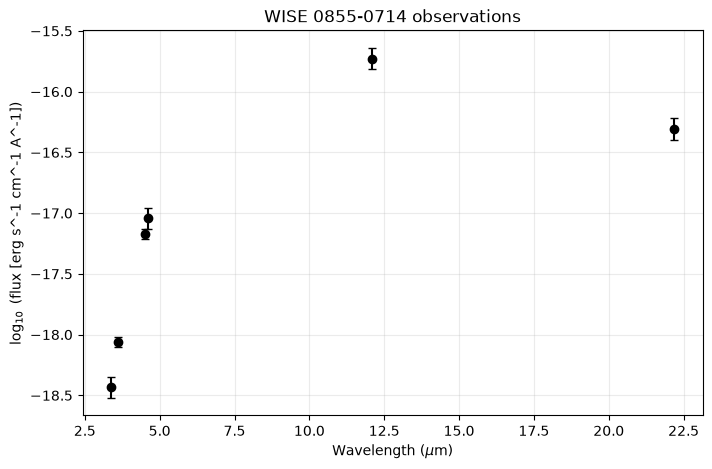

In [3]:
# ------------------------------------------------------------------
# Step 2: Import and inspect the data
# ------------------------------------------------------------------

filename = "data.dat"

# The first seven lines contain the title and column descriptions.
# The numerical data begin on line 8.
data = np.genfromtxt(filename, skip_header=7)

# Extract the three columns.
wavelength_microns = data[:, 0] #wavelength [microns]
observed_log_flux = data[:, 1] #log10(flux [erg s^-1 cm^-1 A^-1])
observed_error = data[:, 2] #error on column 2

# scipy.constants uses SI units, so wavelength must be in meters.
wavelength_m = wavelength_microns * 10**-6

# Inspect the imported data.
print("Shape of data:", data.shape)
print("Number of observations:", len(wavelength_microns))
print()
print("Wavelengths (microns):")
print(wavelength_microns)
print()
print("Observed log10 flux:")
print(observed_log_flux)
print()
print("Log-flux uncertainties:")
print(observed_error)

# ------------------------------------------------------------------
# Data plot
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(
    wavelength_microns,
    observed_log_flux,
    yerr=observed_error,
    fmt="ko",
    capsize=3
)

ax.set_xlabel(r"Wavelength ($\mu$m)")
ax.set_ylabel(r"$\log_{10}$ (flux [erg s^-1 cm^-1 A^-1])")
ax.set_title("WISE 0855-0714 observations")
ax.grid(alpha=0.25)
if save == True:
    fig.savefig("Step_2.WISE0855_data_plot.png", dpi=300, bbox_inches="tight")
plt.show()

### Step 3: Choosing the starting point

I choose a random starting temperature between **200 and 400 K**. This includes the approximate **225–260 K** range mentioned in the lab and also allows warmer starting values.
For the flux scale, a rough estimate at $T=250$ K is

$$
a \approx \operatorname{median}_i\!\left[y_i-\log_{10}B_\lambda(\lambda_i,250\,\mathrm K)\right]
\approx -22.42.
$$ 

I choose a starting range of **−25 to −20**, which comfortably includes this estimate.

These endpoints are practical choices for initializing the chain. During sampling, the parameters can move outside these starting ranges, within the wider prior bounds: $100<T<500$ K and $-30<a<-15$. 
I then remove burn-in and check mixing before summarizing the posterior.

Initial temperature: 354.79 K
Initial log10(alpha): -22.8056
Initial chi-squared: 2942.296
Initial log-likelihood: -1460.614
Initial log-posterior: -1460.614

Observed and predicted log-fluxes:
Wavelength =  3.368 microns, observed = -18.4349, model = -16.5957
Wavelength =  4.618 microns, observed = -17.0421, model = -15.8656
Wavelength = 12.082 microns, observed = -15.7276, model = -15.5827
Wavelength = 22.194 microns, observed = -16.3074, model = -16.1782
Wavelength =  3.600 microns, observed = -18.0625, model = -16.4034
Wavelength =  4.500 microns, observed = -17.1726, model = -15.9094


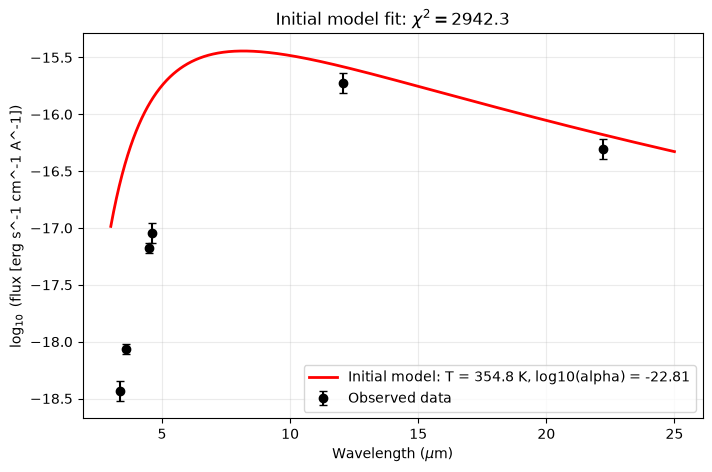

In [4]:
# ------------------------------------------------------------------
# Step 3: Initialize at a random point, calculate chi-squared, log-likelihood and log-posterior, 
# and compare the model with the data
# ------------------------------------------------------------------

# Use a fixed seed so that the random starting point is reproducible.
rng = np.random.default_rng(42)

# Choose a random starting point within a reasonable part of the prior.
initial_temperature = rng.uniform(200.0, 400.0)
initial_log_alpha = rng.uniform(-25.0, -20.0)
# Store the two parameters in one array: parameters[0] = temperature, parameters[1] = log10(alpha)
initial_parameters = np.array([initial_temperature, initial_log_alpha])

# Evaluate chi-squared, log-likelihood, and log-posterior at the initial point.
initial_chi2 = chi_squared(initial_parameters, wavelength_m, observed_log_flux, observed_error)
initial_log_likelihood = log_likelihood(initial_parameters, wavelength_m, observed_log_flux, observed_error)
initial_log_posterior = log_posterior(initial_parameters, wavelength_m, observed_log_flux, observed_error)

print(f"Initial temperature: {initial_temperature:.2f} K")
print(f"Initial log10(alpha): {initial_log_alpha:.4f}")
print(f"Initial chi-squared: {initial_chi2:.3f}")
print(f"Initial log-likelihood: {initial_log_likelihood:.3f}")
print(f"Initial log-posterior: {initial_log_posterior:.3f}")

# Make a smooth wavelength grid for drawing the model curve.
model_wavelength_microns = np.linspace(3.0, 25.0, 1000)
model_wavelength_m = model_wavelength_microns * 1e-6 #wavelengths in meters

# Calculate the model on the smooth grid and at the observed wavelengths.
initial_model_curve = model_log_flux(model_wavelength_m, initial_temperature, initial_log_alpha)
initial_model_at_data = model_log_flux(wavelength_m, initial_temperature, initial_log_alpha)

# Print the observed and predicted values for comparison.
print()
print("Observed and predicted log-fluxes:")

for wavelength, observed, predicted in zip(wavelength_microns, observed_log_flux, initial_model_at_data):
    print(
        f"Wavelength = {wavelength:6.3f} microns, "
        f"observed = {observed:8.4f}, "
        f"model = {predicted:8.4f}"
    )

# ------------------------------------------------------------------
# Plot the data and the model for the initial parameters
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(
    wavelength_microns,
    observed_log_flux,
    yerr=observed_error,
    fmt="ko",
    capsize=3,
    label="Observed data"
)

ax.plot(
    model_wavelength_microns,
    initial_model_curve,
    color="red",
    linewidth=2,
    label=(
        f"Initial model: T = {initial_temperature:.1f} K, "
        f"log10(alpha) = {initial_log_alpha:.2f}"
    )
)

ax.set_xlabel(r"Wavelength ($\mu$m)")
ax.set_ylabel(r"$\log_{10}$ (flux [erg s^-1 cm^-1 A^-1])")
ax.set_title(
    rf"Initial model fit: $\chi^2={initial_chi2:.1f}$"
)
ax.legend()
ax.grid(alpha=0.25)
if save == True:
    fig.savefig("Step_3.WISE0855_initial_model_plot.png", dpi=300, bbox_inches="tight")
plt.show()

Starting parameters: [354.79120971 -22.8056078 ]
Temperature proposal width: 2.0 K
log10(alpha) proposal width: 0.04
Accepted moves: 10000
Total proposed moves: 23923
Acceptance fraction: 0.418
Number of saved chain states: 23924
Final parameters: [247.63188453 -22.38300181]


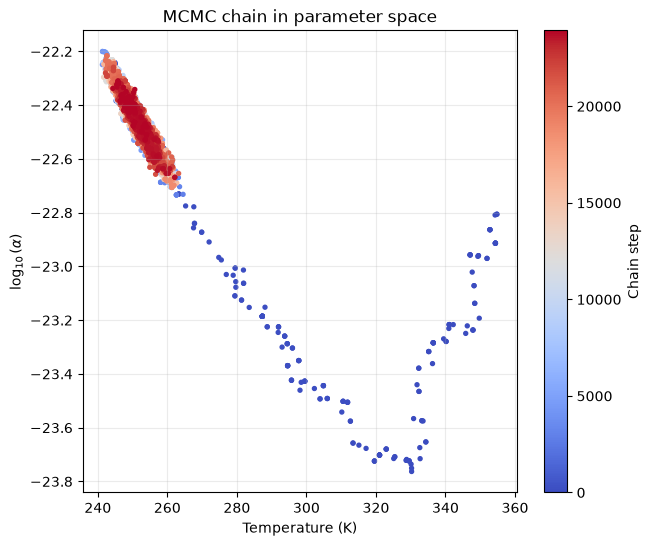

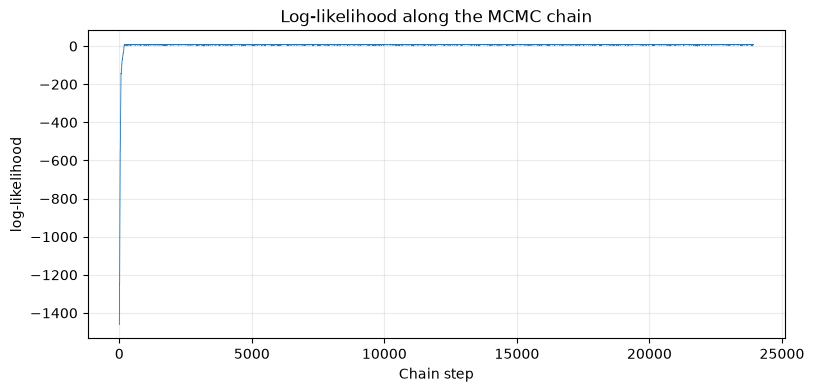

In [5]:
# ------------------------------------------------------------------
# Step 4: Run a Metropolis MCMC with Gaussian proposals
# ------------------------------------------------------------------

def run_metropolis(initial_parameters, target_accepted_moves, temperature_jump, log_alpha_jump, wavelength_m, observed_log_flux, observed_error, random_seed=12345):
    """
    Run a Metropolis MCMC for temperature and log10(alpha) until the target number of proposals is accepted.

    The chain saves the current parameter values after every proposal.
    A rejected proposal therefore adds the same state again.
    """
    rng = np.random.default_rng(random_seed)

    # Start at the point selected in Step 3.
    current_parameters = initial_parameters.copy()
    current_log_posterior = log_posterior(current_parameters, wavelength_m, observed_log_flux, observed_error)

    # Create arrays in which to save the chain.
    # Save the initial point as the first state in the chain.
    chain = [current_parameters.copy()]
    chain_log_posterior = [current_log_posterior]

    accepted_moves = 0
    proposed_moves = 0

    # Continue until the target number of moves has been accepted.
    while accepted_moves < target_accepted_moves:

        # Propose a Gaussian jump in temperature and log10(alpha) (a random change from a normal distribution centered on zero).
        trial_parameters = np.array([current_parameters[0] + rng.normal(0.0, temperature_jump), current_parameters[1] + rng.normal(0.0, log_alpha_jump)])
        trial_log_posterior = log_posterior(trial_parameters, wavelength_m, observed_log_flux, observed_error)

        # Apply the Metropolis rule using log-posterior values.
        if trial_log_posterior > current_log_posterior:
            accept = True
        else:
            acceptance_probability = np.exp(trial_log_posterior - current_log_posterior)
            accept = rng.random() < acceptance_probability

        if accept:
            current_parameters = trial_parameters
            current_log_posterior = trial_log_posterior
            accepted_moves += 1

        # Save the current state after every proposal.
        # If rejected, this repeats the previous state.
        chain.append(current_parameters.copy())
        chain_log_posterior.append(current_log_posterior)
        proposed_moves += 1    

        acceptance_fraction = accepted_moves / proposed_moves    

    return (np.asarray(chain), np.asarray(chain_log_posterior), accepted_moves, proposed_moves, acceptance_fraction)

# ------------------------------------------------------------------
# Run a first trial chain
# ------------------------------------------------------------------
target_accepted_moves = 10000
temperature_jump = 2.0 # K
log_alpha_jump = 0.04

chain, chain_log_posterior, accepted_moves, proposed_moves, acceptance_fraction = run_metropolis(initial_parameters, target_accepted_moves, temperature_jump, log_alpha_jump, wavelength_m, observed_log_flux, observed_error)

print("Starting parameters:", initial_parameters)
print("Temperature proposal width:", temperature_jump, "K")
print("log10(alpha) proposal width:", log_alpha_jump)
print("Accepted moves:", accepted_moves)
print("Total proposed moves:", proposed_moves)
print("Acceptance fraction:", f"{acceptance_fraction:.3f}")
print("Number of saved chain states:", len(chain))
print("Final parameters:", chain[-1])

# ------------------------------------------------------------------
# Plot the full chain to inspect its movement
# ------------------------------------------------------------------
proposal_steps = np.arange(len(chain))

# Parameter-space scatter, colored by chain order
fig = plt.figure(figsize=(7, 6))

points = plt.scatter(
    chain[:, 0],
    chain[:, 1],
    c=proposal_steps,
    cmap="coolwarm",
    s=8
)

plt.xlabel("Temperature (K)")
plt.ylabel(r"$\log_{10}(\alpha)$")
plt.title("MCMC chain in parameter space")
plt.colorbar(points, label="Chain step")
plt.grid(alpha=0.25)
if save == True:
    fig.savefig("Step_4.WISE0855_MCMC_chain_in_parameter_space.png", dpi=300, bbox_inches="tight")
plt.show()

# Log-posterior trace
# Here log-posterior equals log-likelihood for points inside the prior, because the log-prior is 0 inside its allowed bounds.
fig = plt.figure(figsize=(9, 4))

plt.plot(
    proposal_steps,
    chain_log_posterior,
    linewidth=0.6
)

plt.xlabel("Chain step")
plt.ylabel("log-likelihood")
plt.title("Log-likelihood along the MCMC chain")
plt.grid(alpha=0.25)
if save == True:
    fig.savefig("Step_4.WISE0855_chain_plot.png", dpi=300, bbox_inches="tight")
plt.show()

Approximate temperature uncertainty: 3.3 K
Approximate log10(alpha) uncertainty: 0.08
Temperature jump =   2.3 K, log(alpha) jump =  0.060, accepted =  3000, proposed =  8781, acceptance fraction = 0.342
Temperature jump =   2.8 K, log(alpha) jump =  0.070, accepted =  3000, proposed = 10471, acceptance fraction = 0.287
Temperature jump =   2.8 K, log(alpha) jump =  0.090, accepted =  3000, proposed = 12410, acceptance fraction = 0.242
Temperature jump =   3.3 K, log(alpha) jump =  0.080, accepted =  3000, proposed = 12446, acceptance fraction = 0.241
Temperature jump =   3.8 K, log(alpha) jump =  0.070, accepted =  3000, proposed = 12394, acceptance fraction = 0.242
Temperature jump =   3.8 K, log(alpha) jump =  0.090, accepted =  3000, proposed = 14176, acceptance fraction = 0.212
Temperature jump =   4.3 K, log(alpha) jump =  0.100, accepted =  3000, proposed = 16801, acceptance fraction = 0.179


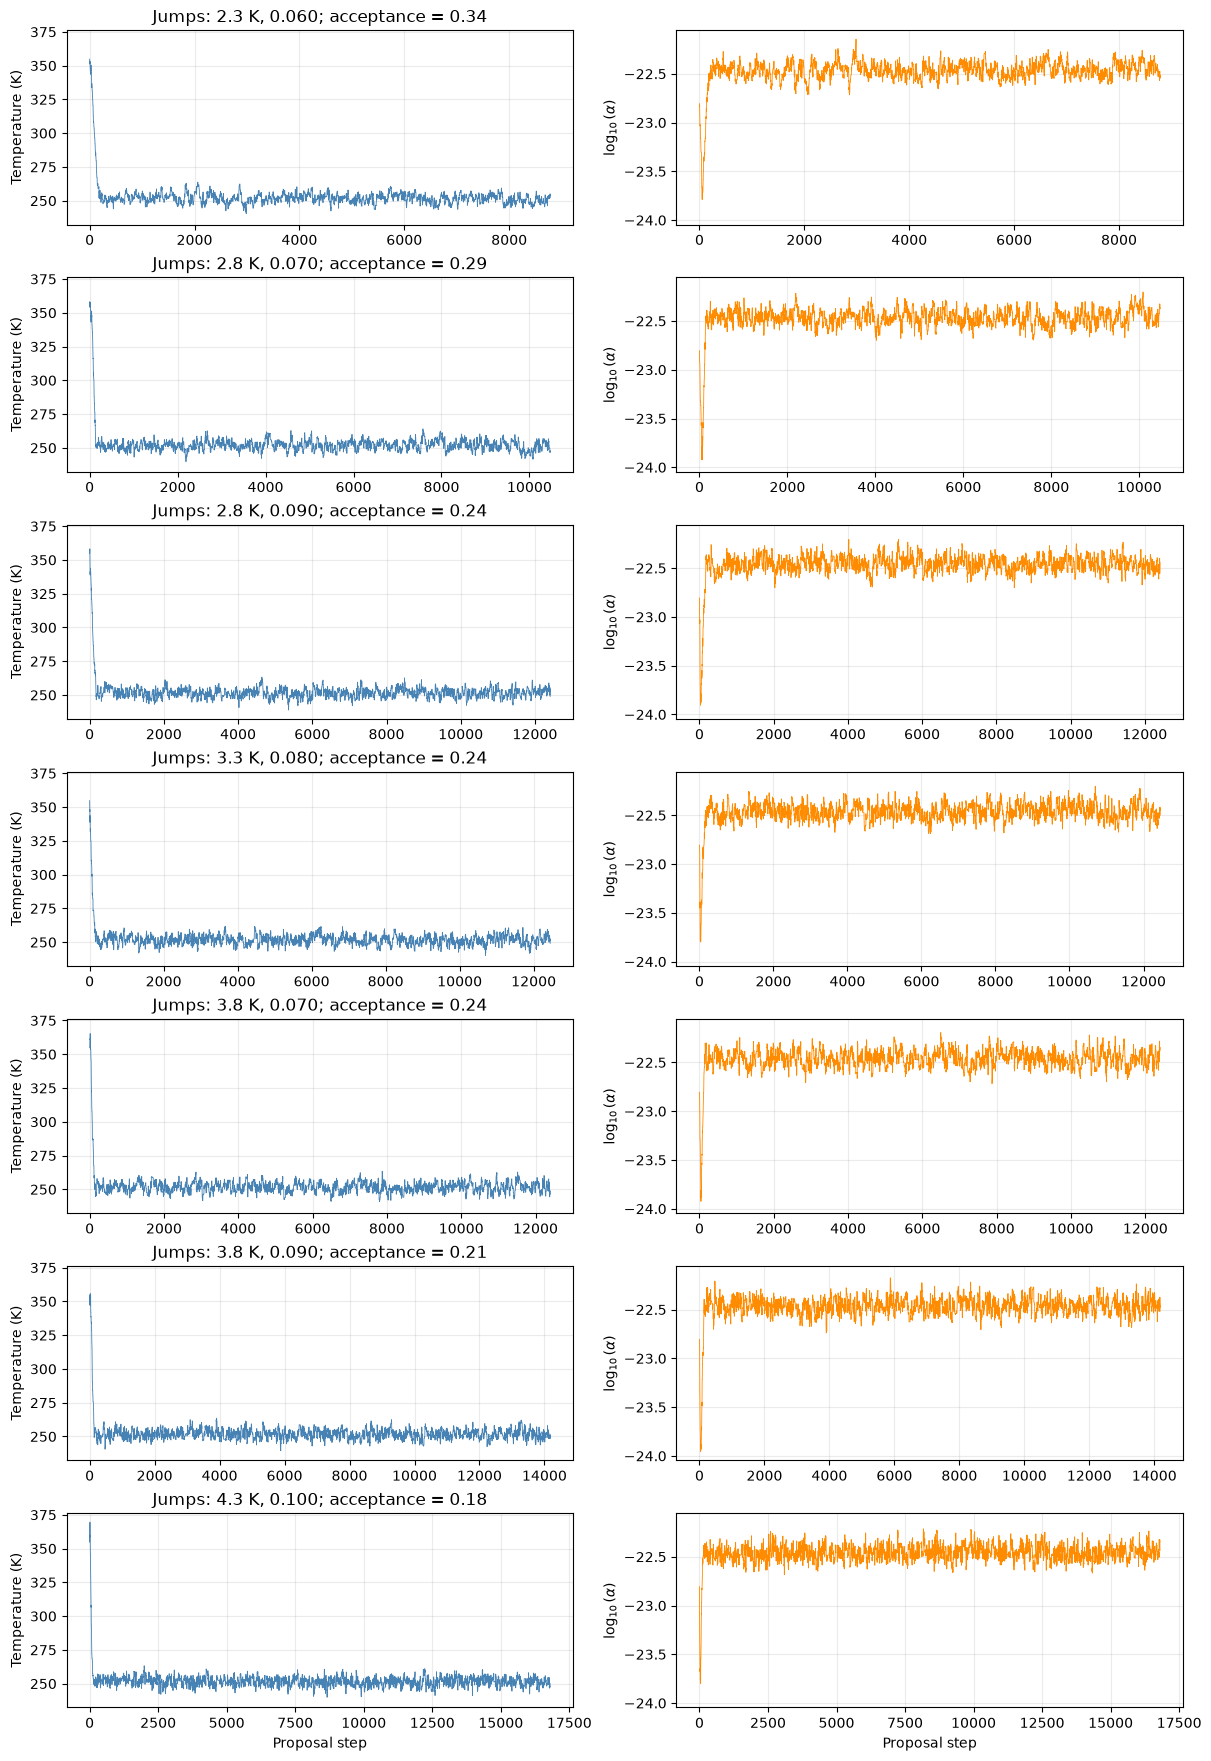

In [6]:
# ------------------------------------------------------------------
# Step 5: Test and tune the Gaussian proposal jump sizes
# ------------------------------------------------------------------

# Use the second half of the Step 4 chain for rough uncertainty estimates.
second_half_chain = chain[len(chain) // 2:]

temperature_uncertainty = np.std(second_half_chain[:, 0])
temperature_uncertainty_rounded = round(temperature_uncertainty, 1)
log_alpha_uncertainty = np.std(second_half_chain[:, 1])
log_alpha_uncertainty_rounded = round(log_alpha_uncertainty, 2)

print(f"Approximate temperature uncertainty: {temperature_uncertainty_rounded} K")
print(f"Approximate log10(alpha) uncertainty: {log_alpha_uncertainty_rounded}")

# Each pair is (temperature jump in K, log10(alpha) jump). 

# Initially, I used the following jump settings, which are now commented out. 
# The new jump settings are based on the rough uncertainty estimates from the first trial chain.
# jump_settings = [
#     (2.0, 0.040),   # Very small moves
#     (2.5, 0.050),   # Small moves
#     (3.0, 0.060),   # Moderate moves
#     (4.5, 0.080),    # Large moves
#     (4.5, 0.090),    # Very large moves
# ]

# Create the complete list of candidate jump settings.
jump_settings = [
    (temperature_uncertainty_rounded - 1.0,
     log_alpha_uncertainty_rounded - 0.02),

    (temperature_uncertainty_rounded - 0.5,
     log_alpha_uncertainty_rounded - 0.01),

    (temperature_uncertainty_rounded,
     log_alpha_uncertainty_rounded),

    (temperature_uncertainty_rounded + 0.5,
     log_alpha_uncertainty_rounded + 0.01),

    (temperature_uncertainty_rounded + 1.0,
     log_alpha_uncertainty_rounded + 0.02),

    (temperature_uncertainty_rounded - 0.5,
     log_alpha_uncertainty_rounded + 0.01),

    (temperature_uncertainty_rounded + 0.5,
     log_alpha_uncertainty_rounded - 0.01)
]

# Round the widths, remove duplicates, and sort.
jump_settings = sorted({
    (round(temperature_jump, 1), round(log_alpha_jump, 2))
    for temperature_jump, log_alpha_jump in jump_settings
})

# For each pair, run until this many proposals have been accepted.
trial_accepted_moves = 3000
trial_results = []

for trial_number, (temperature_jump, log_alpha_jump) in enumerate(jump_settings):
    trial_chain, trial_log_posterior, trial_accepted, trial_proposed, trial_acceptance = (
        run_metropolis(    
            initial_parameters=initial_parameters,
            target_accepted_moves=trial_accepted_moves,
            temperature_jump=temperature_jump,
            log_alpha_jump=log_alpha_jump,
            wavelength_m=wavelength_m,
            observed_log_flux=observed_log_flux,
            observed_error=observed_error,
            random_seed=(1000 + trial_number)
        )
    )

    trial_results.append({
        "temperature_jump": temperature_jump,
        "log_alpha_jump": log_alpha_jump,
        "chain": trial_chain,
        "log_posterior": trial_log_posterior,
        "accepted_moves": trial_accepted,
        "proposed_moves": trial_proposed,
        "acceptance_fraction": trial_acceptance
    })

    print(
        f"Temperature jump = {temperature_jump:5.1f} K, "
        f"log(alpha) jump = {log_alpha_jump:6.3f}, "
        f"accepted = {trial_accepted:5d}, "
        f"proposed = {trial_proposed:5d}, "
        f"acceptance fraction = {trial_acceptance:.3f}"
    )
    
# ------------------------------------------------------------------
# Plot temperature and log10(alpha) traces for each trial
# ------------------------------------------------------------------
number_of_trials = len(trial_results)

fig, axes = plt.subplots(
    number_of_trials,
    2,
    figsize=(12, 2.5 * number_of_trials),
    sharey="col",
    constrained_layout=True
)

for row, result in enumerate(trial_results):

    trial_chain = result["chain"]

    axes[row, 0].plot(
        trial_chain[:, 0],
        color="steelblue",
        linewidth=0.6
    )
    axes[row, 0].set_ylabel("Temperature (K)")
    axes[row, 0].set_title(
        f"Jumps: {result['temperature_jump']:.1f} K, "
        f"{result['log_alpha_jump']:.3f}; "
        f"acceptance = {result['acceptance_fraction']:.2f}"
    )
    axes[row, 0].grid(alpha=0.25)

    axes[row, 1].plot(
        trial_chain[:, 1],
        color="darkorange",
        linewidth=0.6
    )
    axes[row, 1].set_ylabel(r"$\log_{10}(\alpha)$")
    axes[row, 1].grid(alpha=0.25)

axes[-1, 0].set_xlabel("Proposal step")
axes[-1, 1].set_xlabel("Proposal step")
if save == True:
    fig.savefig("Step_5.WISE0855_MCMC_trial_chains.png", dpi=300, bbox_inches="tight")
plt.show()

**Choosing the jump sizes.** The second half of the Step 4 chain gives rough standard deviations of 3.4 K and 0.08. These help us choose trial widths; they are not the final uncertainties. We test nearby pairs, including the 3.3 K and 0.08 used in the main run. That run accepts about 25% of proposals, and the separate chains in Step 8 give similar results. These widths work well here, but the acceptance fraction alone does not tell us which pair is best. We also look for steady movement and few long flat stretches in the traces. The plots above show the full trial chains on matching y-scales.

MCMC run with chosen jump sizes:
Chosen temperature jump: 3.3 K
Chosen log10(alpha) jump: 0.08
Accepted moves: 10000
Total proposed moves: 41521
Acceptance fraction: 0.241
Number of saved chain states: 41522


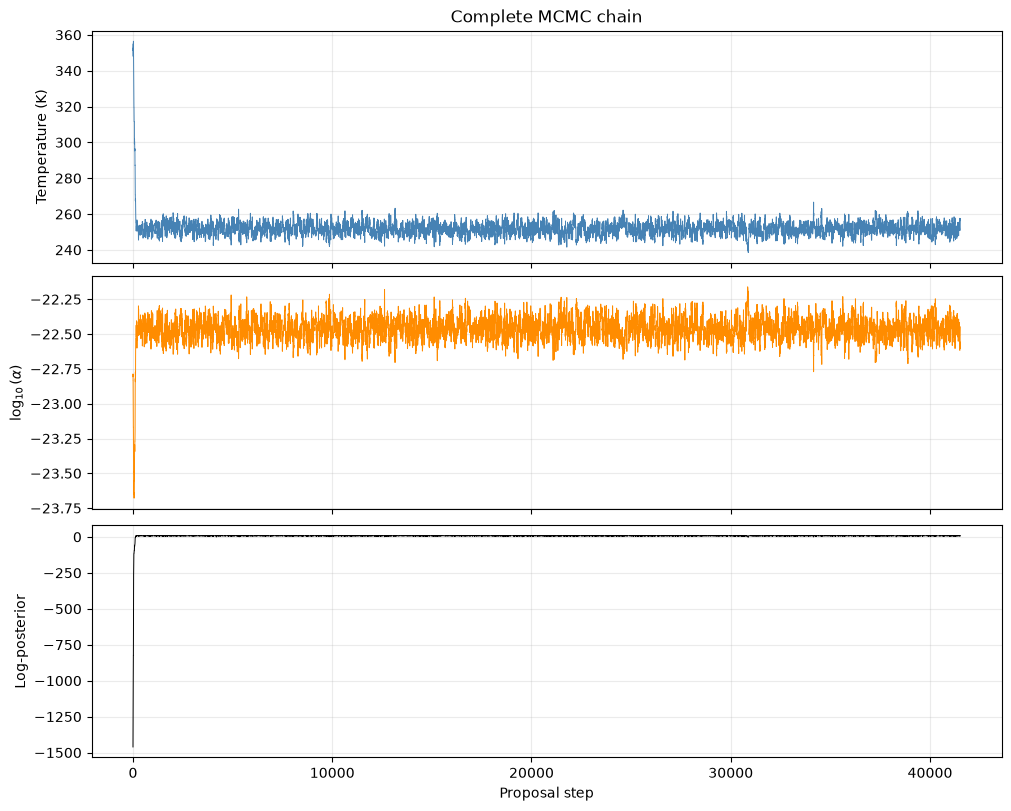

In [7]:
# ------------------------------------------------------------------
# Select the jump sizes and run a longer chain to get a good sample of the posterior
# ------------------------------------------------------------------

# These moderate values should give a useful acceptance fraction for this dataset.
chosen_temperature_jump = 3.3
chosen_log_alpha_jump = 0.080

target_accepted_moves = 10000

chain, chain_log_posterior, accepted_moves, proposed_moves, acceptance_fraction = run_metropolis(
    initial_parameters=initial_parameters,
    target_accepted_moves=target_accepted_moves,
    temperature_jump=chosen_temperature_jump,
    log_alpha_jump=chosen_log_alpha_jump,
    wavelength_m=wavelength_m,
    observed_log_flux=observed_log_flux,
    observed_error=observed_error,
    random_seed=2026
)
print("MCMC run with chosen jump sizes:")
print("Chosen temperature jump:", chosen_temperature_jump, "K")
print("Chosen log10(alpha) jump:", chosen_log_alpha_jump)
print("Accepted moves:", accepted_moves)
print("Total proposed moves:", proposed_moves)
print("Acceptance fraction:", f"{acceptance_fraction:.3f}")
print("Number of saved chain states:", len(chain))

# ------------------------------------------------------------------
# Plot the complete chain
# ------------------------------------------------------------------
fig, axes = plt.subplots(
    3, 1,
    figsize=(10, 8),
    sharex=True,
    constrained_layout=True
)

axes[0].plot(chain[:, 0], color="steelblue", linewidth=0.7)
axes[0].set_ylabel("Temperature (K)")
axes[0].set_title("Complete MCMC chain")
axes[0].grid(alpha=0.25)

axes[1].plot(chain[:, 1], color="darkorange", linewidth=0.7)
axes[1].set_ylabel(r"$\log_{10}(\alpha)$")
axes[1].grid(alpha=0.25)

axes[2].plot(chain_log_posterior, color="black", linewidth=0.7)
axes[2].set_xlabel("Proposal step")
axes[2].set_ylabel("Log-posterior")
axes[2].grid(alpha=0.25)
if save == True:
    fig.savefig("Step_5.WISE0855_MCMC_chain_plot.png", dpi=300, bbox_inches="tight")
plt.show()

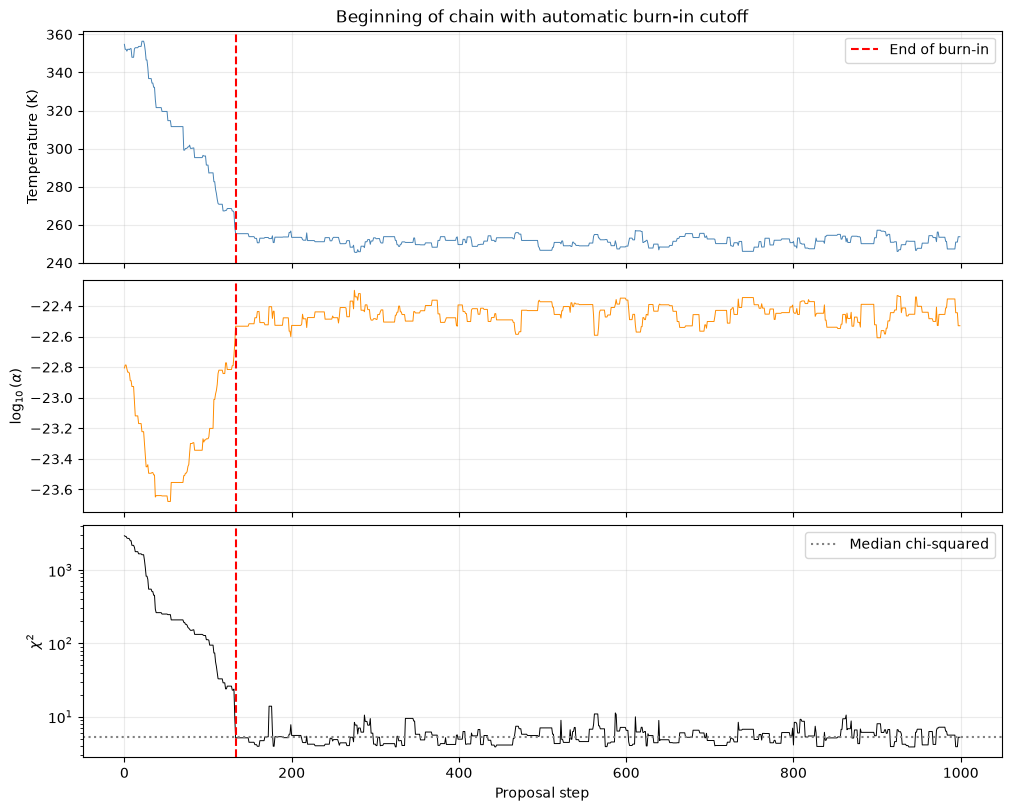

Chi-squared burn-in threshold: 5.2063
Burn-in states removed: 133
Post-burn-in states retained: 41389
First retained temperature: 255.30461849220168 K
First retained log10(alpha): -22.532480406823495


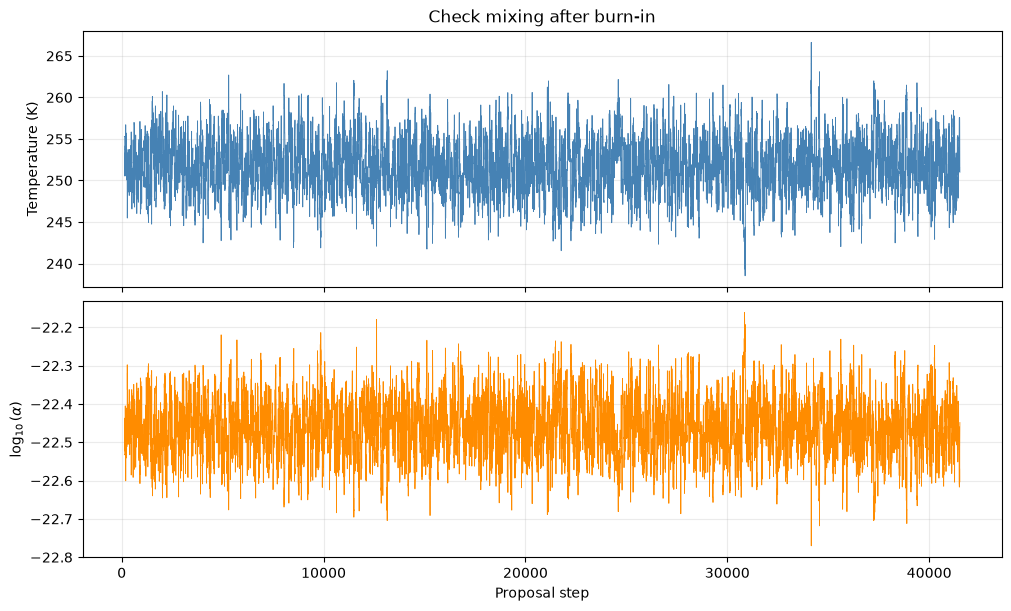

In [8]:
# ------------------------------------------------------------------
# Step 6: Filter out burn-in points
# ------------------------------------------------------------------

# The first chi-squared below the full-chain median marks burn-in.
chain_chi2 = np.array([chi_squared(parameters, wavelength_m, observed_log_flux, observed_error) for parameters in chain])
chi2_burn_point = np.median(chain_chi2)
burn_in = np.flatnonzero(chain_chi2 < chi2_burn_point)[0]

# Zoom into the beginning to show the automatic burn-in crossing.
# This changes the display only; the cutoff uses the complete chain.
burn_in_plot_end = 1000
fig, axes = plt.subplots(
    3, 1,
    figsize=(10, 8),
    sharex=True,
    constrained_layout=True
)
axes[0].plot(chain[:burn_in_plot_end, 0], color="steelblue", linewidth=0.7)
axes[0].axvline(burn_in, color="red", linestyle="--", label="End of burn-in")
axes[0].set_ylabel("Temperature (K)")
axes[0].set_title("Beginning of chain with automatic burn-in cutoff")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(chain[:burn_in_plot_end, 1], color="darkorange", linewidth=0.7)
axes[1].axvline(burn_in, color="red", linestyle="--")
axes[1].set_ylabel(r"$\log_{10}(\alpha)$")
axes[1].grid(alpha=0.25)

axes[2].plot(chain_chi2[:burn_in_plot_end], color="black", linewidth=0.7)
axes[2].axhline(chi2_burn_point, color="gray", linestyle=":", label="Median chi-squared")
axes[2].set_yscale("log")
axes[2].legend()
axes[2].axvline(burn_in, color="red", linestyle="--")
axes[2].set_xlabel("Proposal step")
axes[2].set_ylabel(r"$\chi^2$")
axes[2].grid(alpha=0.25)
if save == True:
    fig.savefig("Step_6.WISE0855_MCMC_burn_in_crossing.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# Remove burn-in and inspect
# ------------------------------------------------------------------
posterior_chain = chain[burn_in:]
posterior_log_posterior = chain_log_posterior[burn_in:]

temperature_samples = posterior_chain[:, 0]
log_alpha_samples = posterior_chain[:, 1]

print(f"Chi-squared burn-in threshold: {chi2_burn_point:.4f}")
print("Burn-in states removed:", burn_in)
print("Post-burn-in states retained:", len(posterior_chain))
print("First retained temperature:", temperature_samples[0], "K")
print("First retained log10(alpha):", log_alpha_samples[0])

# These post-burn-in traces are mixing-check plots.
posterior_steps = np.arange(burn_in, len(chain))

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 6),
    sharex=True,
    constrained_layout=True
)
axes[0].plot(posterior_steps, temperature_samples, color="steelblue", linewidth=0.6)
axes[0].set_ylabel("Temperature (K)")
axes[0].set_title("Check mixing after burn-in")
axes[0].grid(alpha=0.25)

axes[1].plot(posterior_steps, log_alpha_samples, color="darkorange", linewidth=0.6)
axes[1].set_xlabel("Proposal step")
axes[1].set_ylabel(r"$\log_{10}(\alpha)$")
axes[1].grid(alpha=0.25)
if save == True:
    fig.savefig("Step_6.WISE0855_MCMC_post_burn_in_traces.png", dpi=300, bbox_inches="tight")
plt.show()

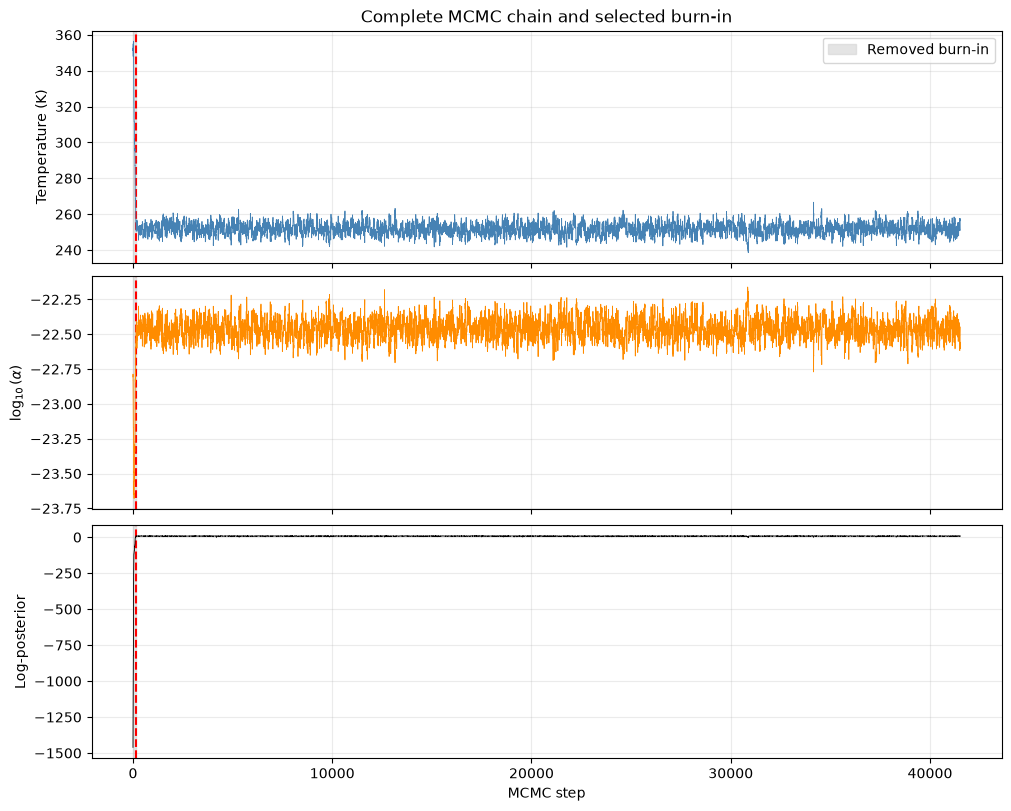

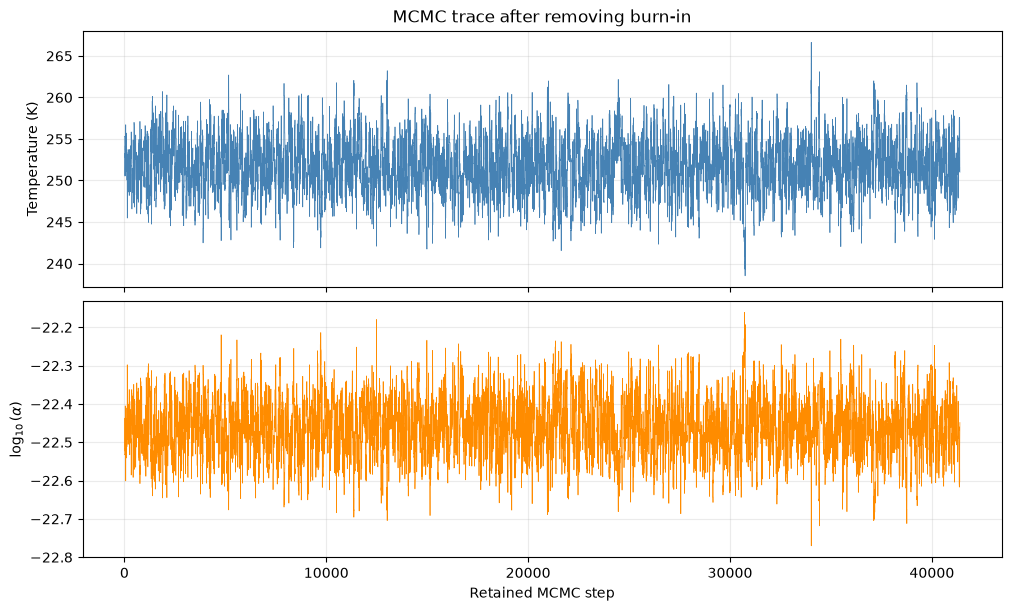

Medians from four sections of the retained chain:
Section 1: T median = 251.799 K, log10(alpha) median = -22.4638
Section 2: T median = 251.572 K, log10(alpha) median = -22.4577
Section 3: T median = 251.778 K, log10(alpha) median = -22.4609
Section 4: T median = 251.745 K, log10(alpha) median = -22.4630

Temperature = 251.72 - 3.28 + 3.26 K
log10(alpha) = -22.4612 - 0.0739 + 0.0748


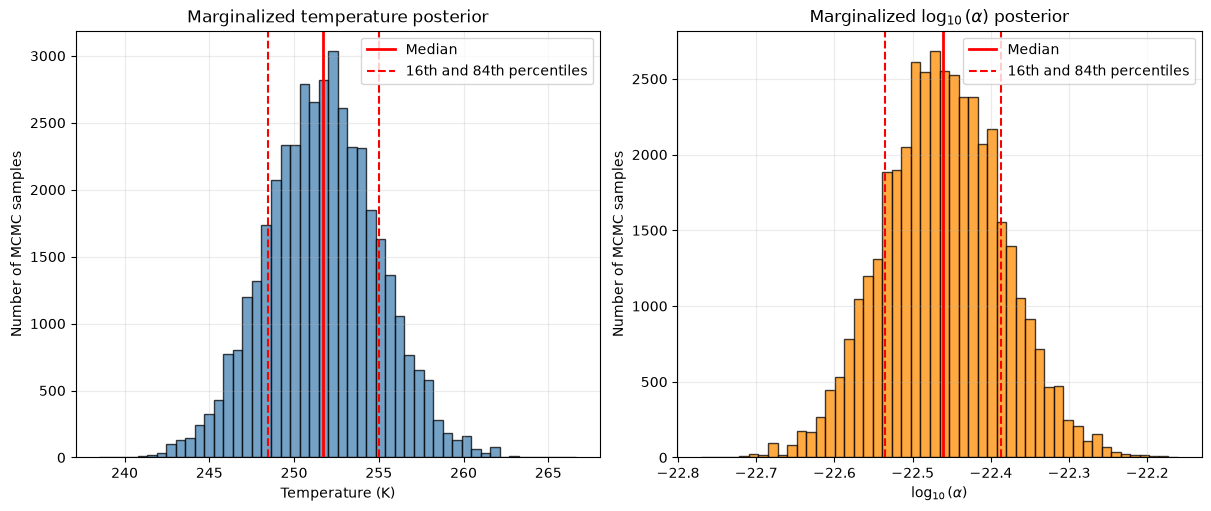

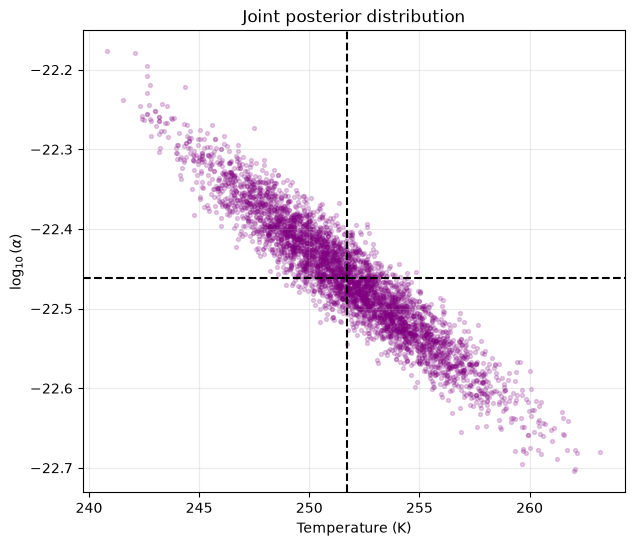

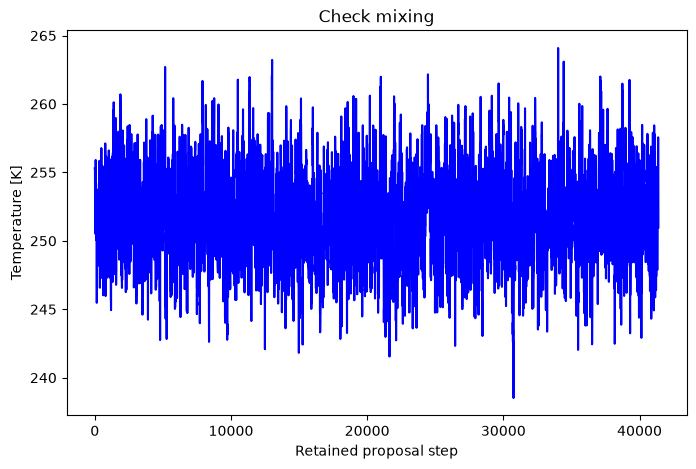

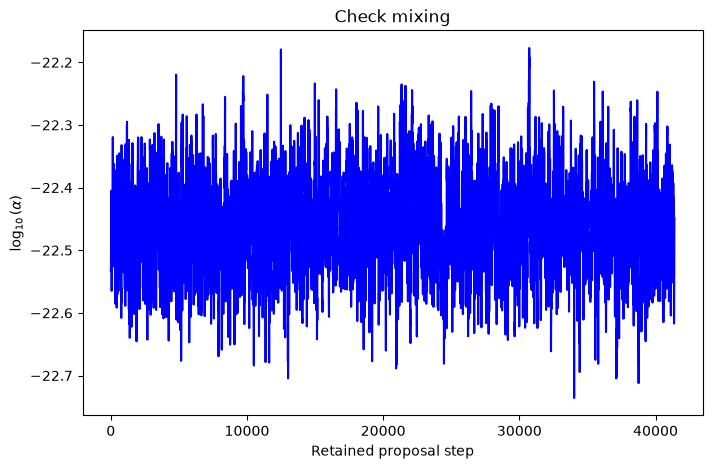

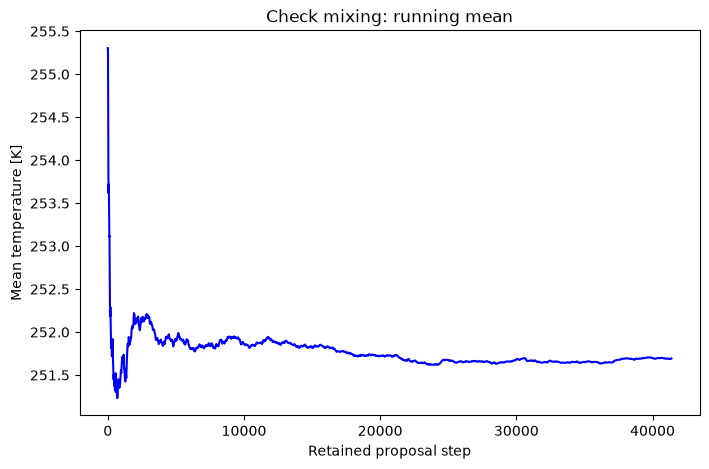

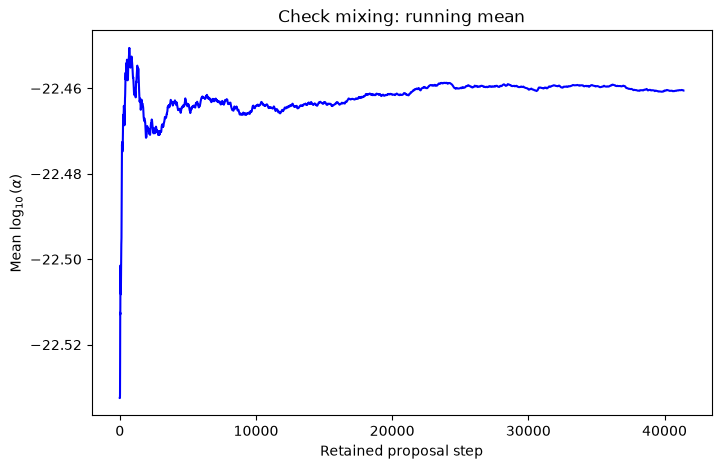

In [9]:
# ------------------------------------------------------------------
# Step 7: Check burn-in and mixing, and plot the posteriors
# ------------------------------------------------------------------

# ------------------------------------------------------------------
# Plot the complete chain and mark the burn-in
# ------------------------------------------------------------------
fig, axes = plt.subplots(
    3,
    1,
    figsize=(10, 8),
    sharex=True,
    constrained_layout=True
)

# Shade the part of the chain that is removed as burn-in.
for ax in axes:
    ax.axvspan(
        0,
        burn_in,
        color="lightgray",
        alpha=0.6,
        label="Removed burn-in"
    )

    ax.axvline(
        burn_in,
        color="red",
        linestyle="--",
        linewidth=1.5
    )

# Temperature trace
axes[0].plot(
    chain[:, 0],
    color="steelblue",
    linewidth=0.6
)

axes[0].set_ylabel("Temperature (K)")
axes[0].set_title("Complete MCMC chain and selected burn-in")
axes[0].legend()
axes[0].grid(alpha=0.25)

# log10(alpha) trace
axes[1].plot(
    chain[:, 1],
    color="darkorange",
    linewidth=0.6
)

axes[1].set_ylabel(r"$\log_{10}(\alpha)$")
axes[1].grid(alpha=0.25)

# Log-posterior trace
axes[2].plot(
    chain_log_posterior,
    color="black",
    linewidth=0.6
)

axes[2].set_xlabel("MCMC step")
axes[2].set_ylabel("Log-posterior")
axes[2].grid(alpha=0.25)
if save == True:
    fig.savefig("Step_7.WISE0855_full_chain_burn_in.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# 2. Plot only the samples retained after burn-in
# ------------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(10, 6),
    sharex=True,
    constrained_layout=True
)

axes[0].plot(
    temperature_samples,
    color="steelblue",
    linewidth=0.5
)

axes[0].set_ylabel("Temperature (K)")
axes[0].set_title("MCMC trace after removing burn-in")
axes[0].grid(alpha=0.25)

axes[1].plot(
    log_alpha_samples,
    color="darkorange",
    linewidth=0.5
)

axes[1].set_xlabel("Retained MCMC step")
axes[1].set_ylabel(r"$\log_{10}(\alpha)$")
axes[1].grid(alpha=0.25)
if save == True:
    fig.savefig("Step_7.WISE0855_retained_chain.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# 3. Compare different sections of the retained chain
# ------------------------------------------------------------------

# Divide the post-burn-in chain into four sections.
chain_sections = np.array_split(posterior_chain, 4)

print("Medians from four sections of the retained chain:")

for section_number, section in enumerate(chain_sections, start=1):

    section_temperature_median = np.median(section[:, 0])
    section_log_alpha_median = np.median(section[:, 1])

    print(
        f"Section {section_number}: "
        f"T median = {section_temperature_median:.3f} K, "
        f"log10(alpha) median = "
        f"{section_log_alpha_median:.4f}"
    )

# ------------------------------------------------------------------
# 4. Calculate posterior medians and 68% credible intervals
# ------------------------------------------------------------------

temperature_16, temperature_median, temperature_84 = (np.percentile(temperature_samples,[16, 50, 84]))

log_alpha_16, log_alpha_median, log_alpha_84 = (np.percentile(log_alpha_samples,[16, 50, 84]))

# Calculate the upper and lower uncertainties.
temperature_lower_error = (temperature_median - temperature_16)
temperature_upper_error = (temperature_84 - temperature_median)
log_alpha_lower_error = (log_alpha_median - log_alpha_16)
log_alpha_upper_error = (log_alpha_84 - log_alpha_median)

print()
print(
    f"Temperature = {temperature_median:.2f} "
    f"- {temperature_lower_error:.2f} "
    f"+ {temperature_upper_error:.2f} K"
)

print(
    f"log10(alpha) = {log_alpha_median:.4f} "
    f"- {log_alpha_lower_error:.4f} "
    f"+ {log_alpha_upper_error:.4f}"
)

# ------------------------------------------------------------------
# 5. Plot the marginalized posterior distributions
# ------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5),
    constrained_layout=True
)

# Temperature posterior
axes[0].hist(
    temperature_samples,
    bins=50,
    color="steelblue",
    alpha=0.75,
    edgecolor="black"
)

axes[0].axvline(
    temperature_median,
    color="red",
    linewidth=2,
    label="Median"
)

axes[0].axvline(
    temperature_16,
    color="red",
    linestyle="--",
    label="16th and 84th percentiles"
)

axes[0].axvline(
    temperature_84,
    color="red",
    linestyle="--"
)

axes[0].set_xlabel("Temperature (K)")
axes[0].set_ylabel("Number of MCMC samples")
axes[0].set_title("Marginalized temperature posterior")
axes[0].legend()
axes[0].grid(alpha=0.25)

# log10(alpha) posterior
axes[1].hist(
    log_alpha_samples,
    bins=50,
    color="darkorange",
    alpha=0.75,
    edgecolor="black"
)

axes[1].axvline(
    log_alpha_median,
    color="red",
    linewidth=2,
    label="Median"
)

axes[1].axvline(
    log_alpha_16,
    color="red",
    linestyle="--",
    label="16th and 84th percentiles"
)

axes[1].axvline(
    log_alpha_84,
    color="red",
    linestyle="--"
)

axes[1].set_xlabel(r"$\log_{10}(\alpha)$")
axes[1].set_ylabel("Number of MCMC samples")
axes[1].set_title(
    r"Marginalized $\log_{10}(\alpha)$ posterior"
)
axes[1].legend()
axes[1].grid(alpha=0.25)
if save == True:
    fig.savefig("Step_7.WISE0855_marginalized_posteriors.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# 6. Plot the joint posterior distribution
# ------------------------------------------------------------------

# Plot every tenth sample so the figure is not overcrowded.
plotting_samples = posterior_chain[::10]

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    plotting_samples[:, 0],
    plotting_samples[:, 1],
    s=8,
    alpha=0.2,
    color="purple"
)

ax.axvline(
    temperature_median,
    color="black",
    linestyle="--"
)

ax.axhline(
    log_alpha_median,
    color="black",
    linestyle="--"
)

ax.set_xlabel("Temperature (K)")
ax.set_ylabel(r"$\log_{10}(\alpha)$")
ax.set_title("Joint posterior distribution")
ax.grid(alpha=0.25)
if save == True:
    fig.savefig("Step_7.WISE0855_joint_posterior.png", dpi=300, bbox_inches="tight")
plt.show()

# Thin only for display; retain posterior_chain unchanged for analysis.
trace_stride = max(1, len(posterior_chain) // 10000)
trace_chain = posterior_chain[::trace_stride]
trace_steps = np.arange(len(posterior_chain))[::trace_stride]

fig = plt.figure(figsize=(8, 5))
plt.plot(trace_steps, trace_chain[:, 0], color="blue")
plt.title("Check mixing")
plt.xlabel("Retained proposal step")
plt.ylabel("Temperature [K]")
if save == True:
    fig.savefig("Step_7.WISE0855_temperature_mixing.png", dpi=300, bbox_inches="tight")
plt.show()

fig = plt.figure(figsize=(8, 5))
plt.plot(trace_steps, trace_chain[:, 1], color="blue")
plt.title("Check mixing")
plt.xlabel("Retained proposal step")
plt.ylabel(r"$\log_{10}(\alpha)$")
if save == True:
    fig.savefig("Step_7.WISE0855_log_alpha_mixing.png", dpi=300, bbox_inches="tight")
plt.show()

# Running means use every retained state; subsample only the display.
trace_stride = max(1, len(posterior_chain) // 10000)
running_means = np.cumsum(posterior_chain, axis=0) / np.arange(1, len(posterior_chain) + 1)[:, None]
trace_steps = np.arange(len(posterior_chain))[::trace_stride]

fig = plt.figure(figsize=(8, 5))
plt.plot(trace_steps, running_means[::trace_stride, 0], color="blue")
plt.title("Check mixing: running mean")
plt.xlabel("Retained proposal step")
plt.ylabel("Mean temperature [K]")
if save == True:
    fig.savefig("Step_7.WISE0855_temperature_running_mean.png", dpi=300, bbox_inches="tight")
plt.show()

fig = plt.figure(figsize=(8, 5))
plt.plot(trace_steps, running_means[::trace_stride, 1], color="blue")
plt.title("Check mixing: running mean")
plt.xlabel("Retained proposal step")
plt.ylabel(r"Mean $\log_{10}(\alpha)$")
if save == True:
    fig.savefig("Step_7.WISE0855_log_alpha_running_mean.png", dpi=300, bbox_inches="tight")
plt.show()

Chain 1
  Starting parameters: [299.61525725 -22.71384385]
  Accepted proposals: 50000
  Total proposals: 206899
  Acceptance fraction: 0.242
  Saved states: 206900
  Burn-in states removed: 82
  Post-burn-in temperature median: 251.59 K
  Post-burn-in log10(alpha) median: -22.4595

Chain 2
  Starting parameters: [243.70700013 -22.57224308]
  Accepted proposals: 50000
  Total proposals: 206110
  Acceptance fraction: 0.243
  Saved states: 206111
  Burn-in states removed: 21
  Post-burn-in temperature median: 251.68 K
  Post-burn-in log10(alpha) median: -22.4620

Chain 3
  Starting parameters: [235.92871453 -21.06697573]
  Accepted proposals: 50000
  Total proposals: 206870
  Acceptance fraction: 0.242
  Saved states: 206871
  Burn-in states removed: 93
  Post-burn-in temperature median: 251.59 K
  Post-burn-in log10(alpha) median: -22.4595

Chain 4
  Starting parameters: [199.3022954  -22.15943445]
  Accepted proposals: 50000
  Total proposals: 207063
  Acceptance fraction: 0.241
  Save

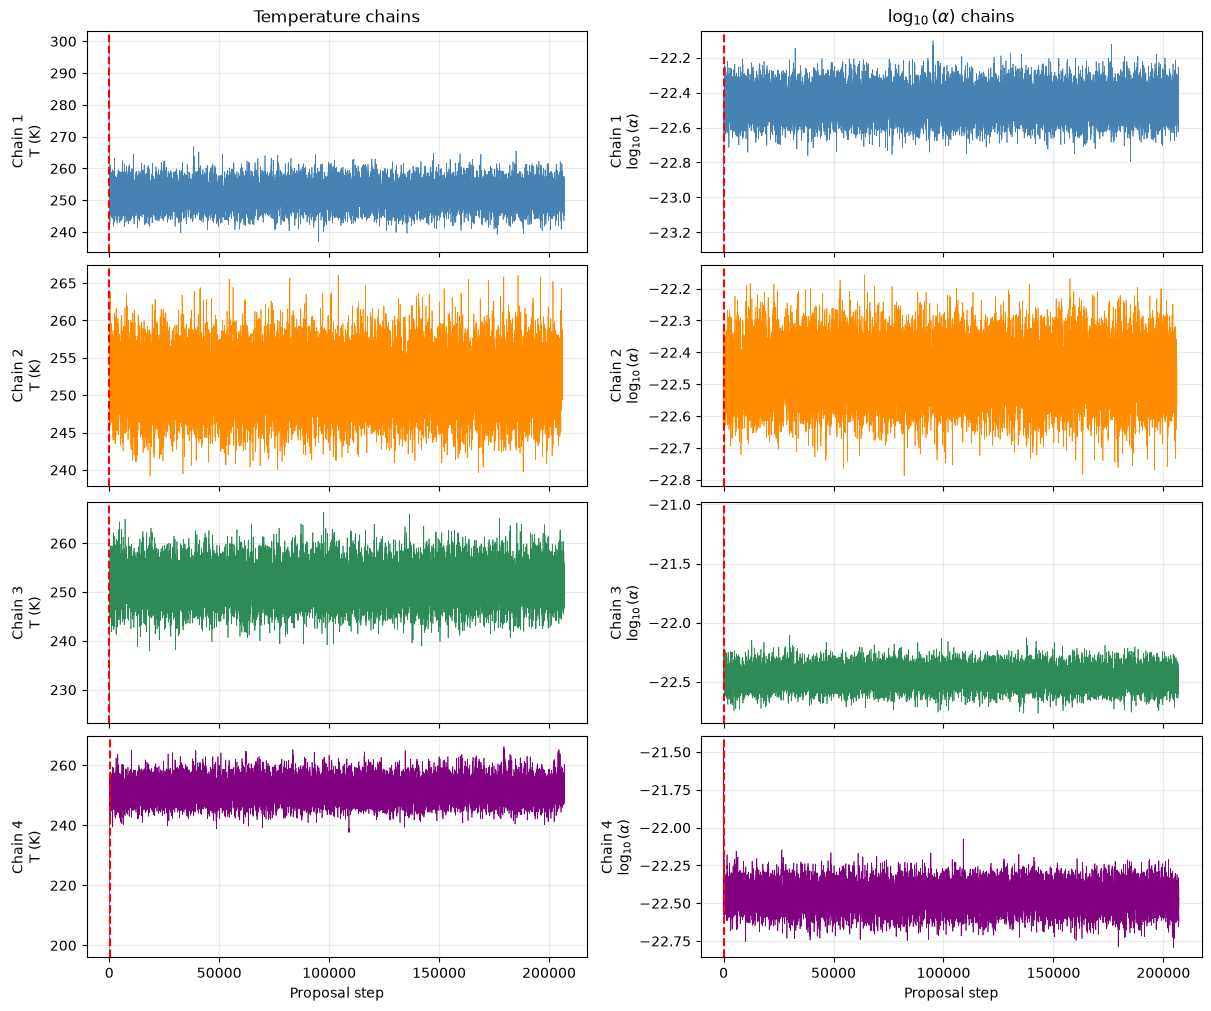

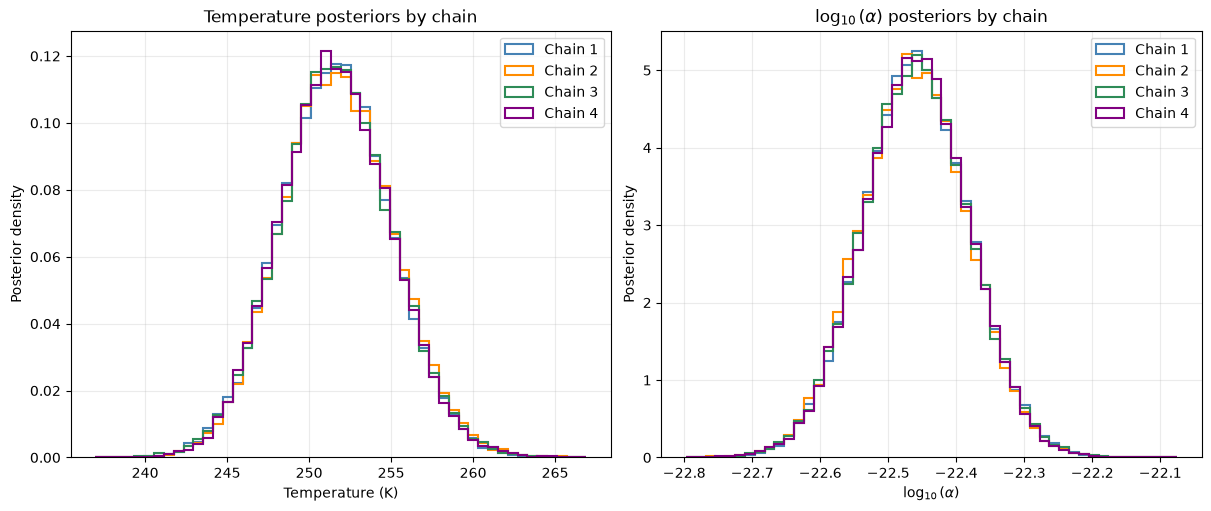

Number of combined post-burn-in states: 826644

Combined temperature: 251.61 -3.33 +3.43 K
Combined log10(alpha): -22.4598 -0.0777 +0.0777


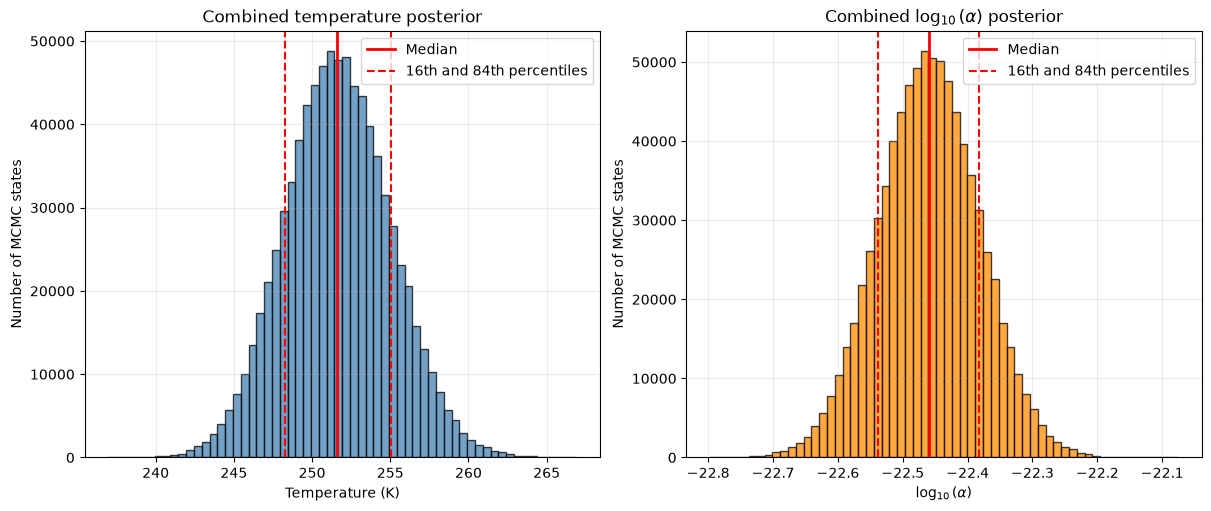

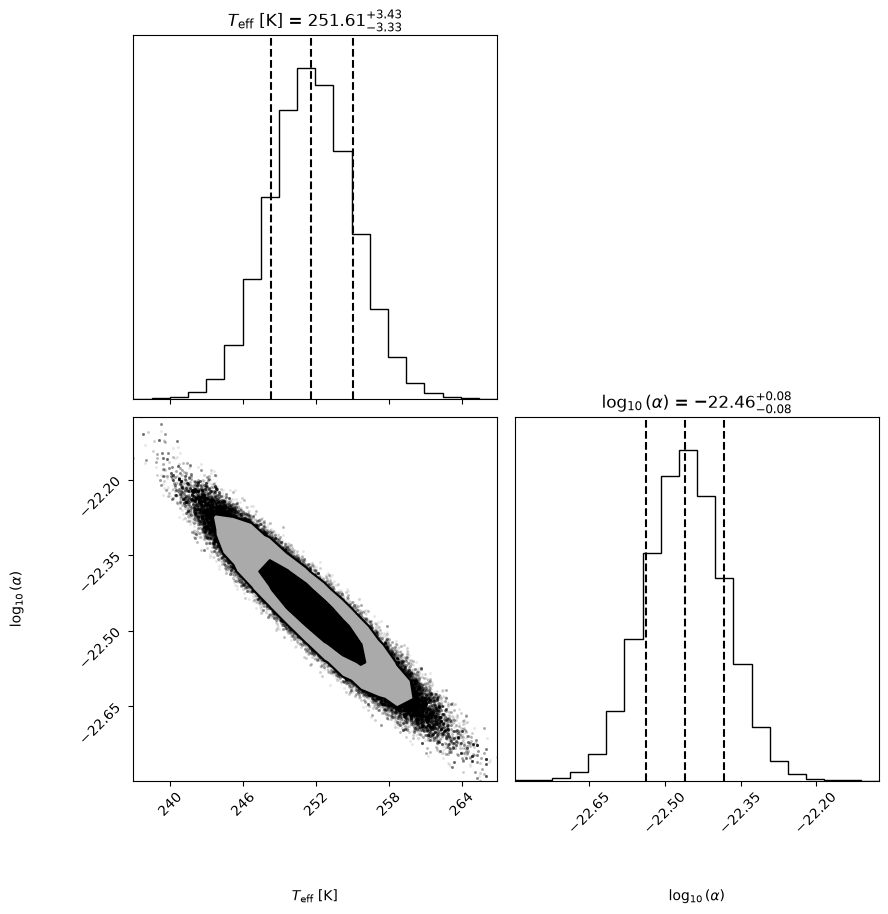

In [10]:
# ------------------------------------------------------------------
# Step 8: Run and combine multiple independent MCMC chains
# ------------------------------------------------------------------

number_of_chains = 4
# run_metropolis stops after this many accepted proposals per chain.
target_accepted_moves_per_chain = 50000

# Use the proposal sizes selected in Step 5.
temperature_jump = chosen_temperature_jump
log_alpha_jump = chosen_log_alpha_jump

# Reproducible generator used only to select starting points.
initialization_rng = np.random.default_rng(9876)

# Give each MCMC chain its own random seed.
chain_seeds = [101, 202, 303, 404]

# Store the results from all chains.
multiple_chain_results = []

for chain_number in range(number_of_chains):
    # Start the chains at different points inside the prior bounds.
    initial_temperature_for_chain = initialization_rng.uniform(180.0, 350.0)
    initial_log_alpha_for_chain = initialization_rng.uniform(-24.0, -21.0)
    starting_parameters = np.array([initial_temperature_for_chain, initial_log_alpha_for_chain])

    # The sampler returns the chain, log-posterior trace, accepted count, proposed count, and acceptance fraction.
    (   current_chain,
        current_log_posterior,
        current_accepted_moves,
        current_proposed_moves,
        current_acceptance
    ) = run_metropolis(
        initial_parameters=starting_parameters,
        target_accepted_moves=target_accepted_moves_per_chain,
        temperature_jump=temperature_jump,
        log_alpha_jump=log_alpha_jump,
        wavelength_m=wavelength_m,
        observed_log_flux=observed_log_flux,
        observed_error=observed_error,
        random_seed=chain_seeds[chain_number]
    )

    # Apply the burn-in rule separately to this chain.
    current_chi2 = np.array([chi_squared(parameters, wavelength_m, observed_log_flux, observed_error) for parameters in current_chain])
    burn_in_per_chain = np.flatnonzero(current_chi2 < np.median(current_chi2))[0]
    current_posterior_chain = current_chain[burn_in_per_chain:]

    multiple_chain_results.append({
        "starting_parameters": starting_parameters,
        "full_chain": current_chain,
        "log_posterior": current_log_posterior,
        "posterior_chain": current_posterior_chain,
        "burn_in": burn_in_per_chain,
        "accepted_moves": current_accepted_moves,
        "proposed_moves": current_proposed_moves,
        "acceptance_fraction": current_acceptance
    })

    print(f"Chain {chain_number + 1}")
    print("  Starting parameters:", starting_parameters)
    print("  Accepted proposals:", current_accepted_moves)
    print("  Total proposals:", current_proposed_moves)
    print(f"  Acceptance fraction: {current_acceptance:.3f}")
    print("  Saved states:", len(current_chain))
    print("  Burn-in states removed:", burn_in_per_chain)
    print(
        "  Post-burn-in temperature median:",
        f"{np.median(current_posterior_chain[:, 0]):.2f} K"
    )
    print(
        "  Post-burn-in log10(alpha) median:",
        f"{np.median(current_posterior_chain[:, 1]):.4f}"
    )
    print()

# ------------------------------------------------------------------
# Plot the individual chains before combining them
# ------------------------------------------------------------------

fig, axes = plt.subplots(
    number_of_chains,
    2,
    figsize=(12, 2.5 * number_of_chains),
    sharex=True,
    constrained_layout=True
)

colors = ["steelblue", "darkorange", "seagreen", "purple"]

for i, result in enumerate(multiple_chain_results):
    current_chain = result["full_chain"]
    chain_steps = np.arange(len(current_chain))

    axes[i, 0].plot(
        chain_steps,
        current_chain[:, 0],
        color=colors[i],
        linewidth=0.5
    )
    axes[i, 0].axvline(
        result["burn_in"],
        color="red",
        linestyle="--",
        label="Burn-in cutoff"
    )
    axes[i, 0].set_ylabel(f"Chain {i + 1}\nT (K)")
    axes[i, 0].grid(alpha=0.25)

    axes[i, 1].plot(
        chain_steps,
        current_chain[:, 1],
        color=colors[i],
        linewidth=0.5
    )
    axes[i, 1].axvline(
        result["burn_in"],
        color="red",
        linestyle="--"
    )
    axes[i, 1].set_ylabel(
        rf"Chain {i + 1}" + "\n" + r"$\log_{10}(\alpha)$"
    )
    axes[i, 1].grid(alpha=0.25)

axes[0, 0].set_title("Temperature chains")
axes[0, 1].set_title(r"$\log_{10}(\alpha)$ chains")
axes[-1, 0].set_xlabel("Proposal step")
axes[-1, 1].set_xlabel("Proposal step")
if save == True:
    fig.savefig("Step_8.WISE0855_independent_chains.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# Compare the post-burn-in posterior histograms from each chain
# ------------------------------------------------------------------

all_temperature_values = np.concatenate([result["posterior_chain"][:, 0] for result in multiple_chain_results])
all_log_alpha_values = np.concatenate([result["posterior_chain"][:, 1] for result in multiple_chain_results])

temperature_bins = np.linspace(np.min(all_temperature_values), np.max(all_temperature_values), 51)
log_alpha_bins = np.linspace(np.min(all_log_alpha_values), np.max(all_log_alpha_values), 51)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

for i, result in enumerate(multiple_chain_results):
    current_posterior = result["posterior_chain"]

    axes[0].hist(
        current_posterior[:, 0],
        bins=temperature_bins,
        density=True,
        histtype="step",
        linewidth=1.5,
        color=colors[i],
        label=f"Chain {i + 1}"
    )
    axes[1].hist(
        current_posterior[:, 1],
        bins=log_alpha_bins,
        density=True,
        histtype="step",
        linewidth=1.5,
        color=colors[i],
        label=f"Chain {i + 1}"
    )

axes[0].set_xlabel("Temperature (K)")
axes[0].set_ylabel("Posterior density")
axes[0].set_title("Temperature posteriors by chain")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].set_xlabel(r"$\log_{10}(\alpha)$")
axes[1].set_ylabel("Posterior density")
axes[1].set_title(r"$\log_{10}(\alpha)$ posteriors by chain")
axes[1].legend()
axes[1].grid(alpha=0.25)
if save == True:
    fig.savefig("Step_8.WISE0855_posteriors_by_chain.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# Combine the post-burn-in chains after checking their traces/histograms
# ------------------------------------------------------------------

combined_posterior_chain = np.vstack([result["posterior_chain"] for result in multiple_chain_results])

combined_temperature_samples = combined_posterior_chain[:, 0]
combined_log_alpha_samples = combined_posterior_chain[:, 1]

print("Number of combined post-burn-in states:", len(combined_posterior_chain))

# ------------------------------------------------------------------
# Calculate final summaries from all combined chains
# ------------------------------------------------------------------

combined_temperature_quantiles = np.percentile(combined_temperature_samples, [16, 50, 84])
combined_log_alpha_quantiles = np.percentile(combined_log_alpha_samples, [16, 50, 84])

temperature_16, temperature_median, temperature_84 = combined_temperature_quantiles
log_alpha_16, log_alpha_median, log_alpha_84 = combined_log_alpha_quantiles

temperature_lower_error = temperature_median - temperature_16
temperature_upper_error = temperature_84 - temperature_median
log_alpha_lower_error = log_alpha_median - log_alpha_16
log_alpha_upper_error = log_alpha_84 - log_alpha_median

print()
print(
    f"Combined temperature: {temperature_median:.2f} "
    f"-{temperature_lower_error:.2f} +{temperature_upper_error:.2f} K"
)
print(
    f"Combined log10(alpha): {log_alpha_median:.4f} "
    f"-{log_alpha_lower_error:.4f} +{log_alpha_upper_error:.4f}"
)

# ------------------------------------------------------------------
# Plot the combined marginalized posteriors
# ------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

axes[0].hist(
    combined_temperature_samples,
    bins=60,
    color="steelblue",
    alpha=0.75,
    edgecolor="black"
)
axes[0].axvline(temperature_median, color="red", linewidth=2, label="Median")
axes[0].axvline(
    temperature_16,
    color="red",
    linestyle="--",
    label="16th and 84th percentiles"
)
axes[0].axvline(temperature_84, color="red", linestyle="--")
axes[0].set_xlabel("Temperature (K)")
axes[0].set_ylabel("Number of MCMC states")
axes[0].set_title("Combined temperature posterior")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].hist(
    combined_log_alpha_samples,
    bins=60,
    color="darkorange",
    alpha=0.75,
    edgecolor="black"
)
axes[1].axvline(log_alpha_median, color="red", linewidth=2, label="Median")
axes[1].axvline(
    log_alpha_16,
    color="red",
    linestyle="--",
    label="16th and 84th percentiles"
)
axes[1].axvline(log_alpha_84, color="red", linestyle="--")
axes[1].set_xlabel(r"$\log_{10}(\alpha)$")
axes[1].set_ylabel("Number of MCMC states")
axes[1].set_title(r"Combined $\log_{10}(\alpha)$ posterior")
axes[1].legend()
axes[1].grid(alpha=0.25)
if save == True:
    fig.savefig("Step_8.WISE0855_combined_posteriors.png", dpi=300, bbox_inches="tight")
plt.show()

# Corner plot of the combined posterior samples
fig = corner.corner(
    combined_posterior_chain,
    labels=[
        r"$T_{\rm eff}$ [K]",
        r"$\log_{10}(\alpha)$"
    ],
    quantiles=[0.16, 0.50, 0.84],
    show_titles=True,
    title_fmt=".2f",
    levels=(0.68, 0.95),
    plot_datapoints=True,
    plot_density=True,
    plot_contours=True,
    fill_contours=True,
    fig=plt.figure(figsize=(10, 10))
)
if save == True:
    fig.savefig("Step_8.WISE0855_combined_corner.png", dpi=300, bbox_inches="tight")
plt.show()

**Main result.** Combining the four chains gives $T=251.61^{+3.43}_{-3.33}$ K and $a=-22.4598^{+0.0777}_{-0.0777}$. We use the median as the estimate and the 16th and 84th percentiles as the limits. This gives a 68% credible interval, roughly the one-sigma interval requested in the lab.

The four temperature medians range from 251.56 to 251.68 K, so the runs agree closely. The corner plot shows that temperature and amplitude are related: a higher temperature can be balanced by a smaller amplitude.

The burn-in rule and plots help us check the chains, but the first crossing of the median-$\chi^2$ threshold does not prove convergence. Nearby states are correlated, so the number of saved states is not the number of independent samples.

Temperature-prior comparison

Uniform in $T$
  Acceptance fraction: 0.245
  Temperature: 251.59 -3.26 +3.44 K
  log10(alpha): -22.4602 -0.0767 +0.0767

Uniform in $\log T$
  Acceptance fraction: 0.243
  Temperature: 251.53 -3.23 +3.58 K
  log10(alpha): -22.4577 -0.0814 +0.0759

Uniform in $T^4$
  Acceptance fraction: 0.240
  Temperature: 251.86 -3.36 +3.32 K
  log10(alpha): -22.4652 -0.0750 +0.0769



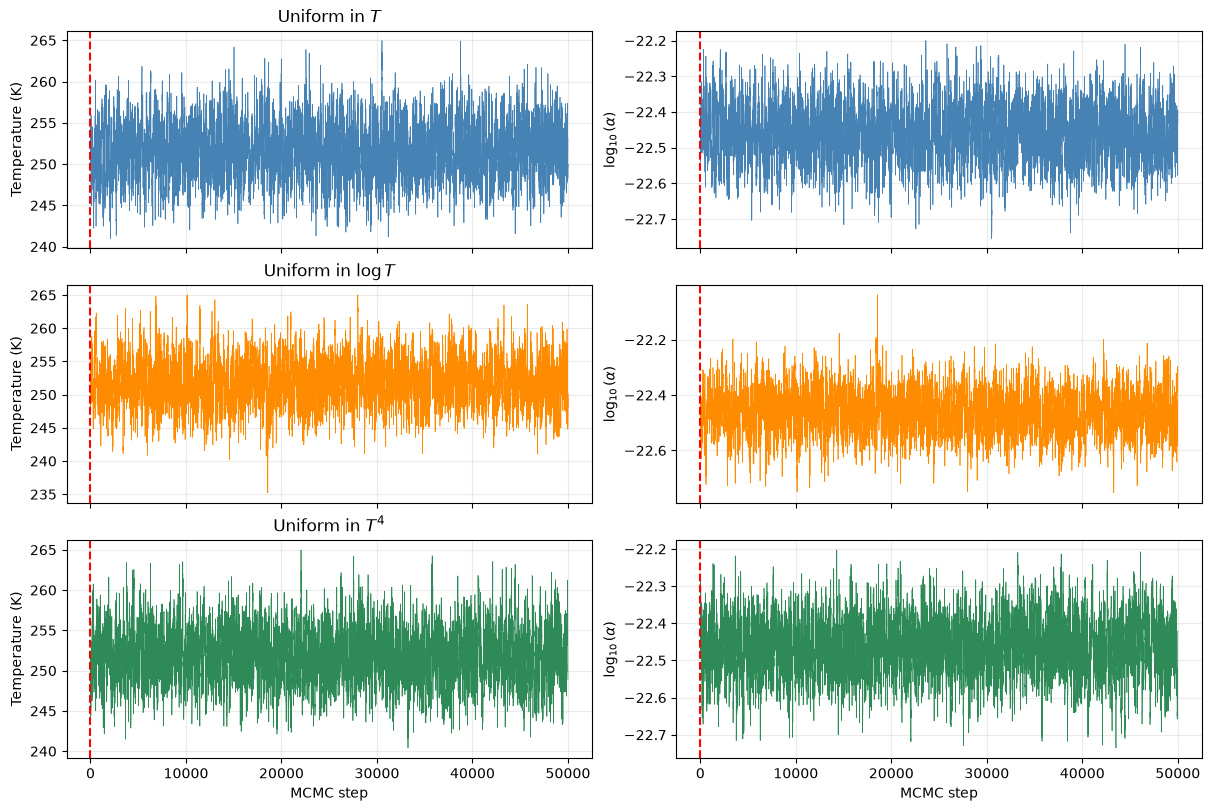

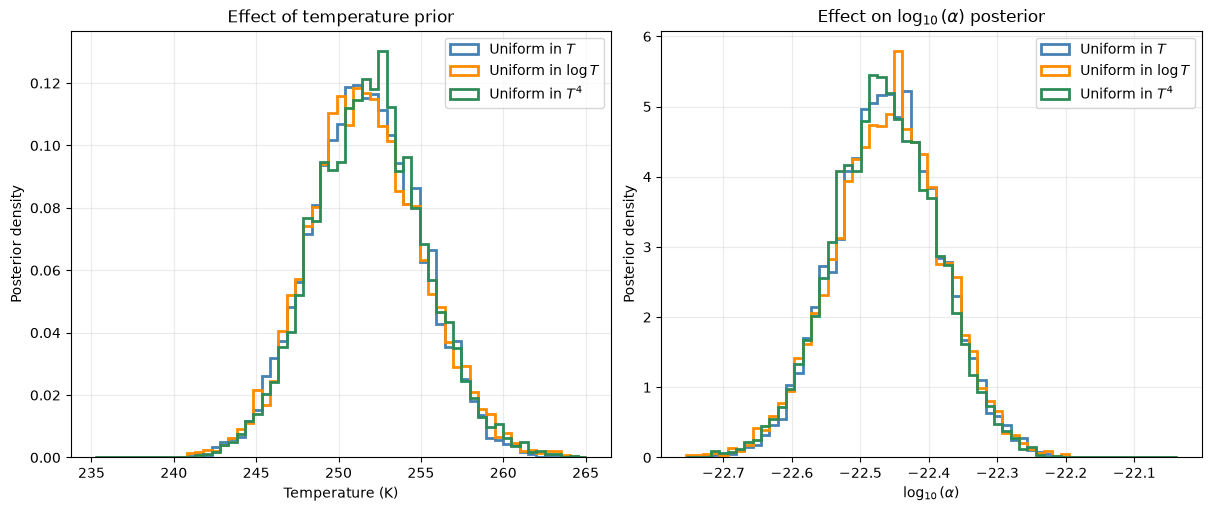

In [11]:
# ------------------------------------------------------------------
# Step 9: Compare different temperature priors
# ------------------------------------------------------------------
def log_prior_with_temperature_choice(parameters, prior_type):
    """
    Log-prior for temperature and log10(alpha).

    prior_type:
        "uniform_T"     : p(T) is constant
        "log_uniform_T" : p(T) is proportional to 1/T
        "uniform_T4"    : p(T) is proportional to T^3
    """
    temperature, log_alpha = parameters

    # Keep the same parameter bounds for all three priors.
    if not (100.0 < temperature < 500.0 and -30.0 < log_alpha < -15.0):
        return -np.inf

    if prior_type == "uniform_T":
        return 0.0

    if prior_type == "log_uniform_T":
        return -np.log(temperature)

    if prior_type == "uniform_T4":
        return 3.0 * np.log(temperature)

def log_posterior_with_temperature_choice(parameters, wavelength_m, observed_log_flux, observed_error, prior_type):
    """Log-posterior for the selected temperature prior."""
    prior = log_prior_with_temperature_choice(parameters, prior_type)

    if not np.isfinite(prior):
        return -np.inf

    likelihood = log_likelihood(parameters, wavelength_m, observed_log_flux, observed_error)

    return prior + likelihood


def run_metropolis_with_temperature_prior(
    initial_parameters,
    number_of_steps,
    temperature_jump,
    log_alpha_jump,
    wavelength_m,
    observed_log_flux,
    observed_error,
    prior_type,
    random_seed
):
    """Run a fixed number of Metropolis proposals for one prior."""
    rng = np.random.default_rng(random_seed)

    chain = np.empty((number_of_steps + 1, 2))
    log_posterior_values = np.empty(number_of_steps + 1)

    current_parameters = initial_parameters.copy()
    current_log_posterior = log_posterior_with_temperature_choice(
        current_parameters,
        wavelength_m,
        observed_log_flux,
        observed_error,
        prior_type
    )

    # Save the initial state before making the first proposal.
    chain[0] = current_parameters
    log_posterior_values[0] = current_log_posterior

    accepted_moves = 0

    for step in range(1, number_of_steps + 1):
        proposed_parameters = np.array([
            current_parameters[0] + rng.normal(0.0, temperature_jump),
            current_parameters[1] + rng.normal(0.0, log_alpha_jump)
        ])

        proposed_log_posterior = log_posterior_with_temperature_choice(
            proposed_parameters,
            wavelength_m,
            observed_log_flux,
            observed_error,
            prior_type
        )

        # For a symmetric Gaussian proposal, this is the Metropolis rule
        # expressed using log-posterior values.
        log_acceptance_ratio = proposed_log_posterior - current_log_posterior

        if np.log(rng.random()) < log_acceptance_ratio:
            current_parameters = proposed_parameters
            current_log_posterior = proposed_log_posterior
            accepted_moves += 1

        chain[step] = current_parameters
        log_posterior_values[step] = current_log_posterior

    acceptance_fraction = accepted_moves / number_of_steps

    return chain, log_posterior_values, acceptance_fraction

# ------------------------------------------------------------------
# Run one chain for each temperature prior
# ------------------------------------------------------------------
prior_types = ["uniform_T", "log_uniform_T", "uniform_T4"]

prior_labels = {
    "uniform_T": r"Uniform in $T$",
    "log_uniform_T": r"Uniform in $\log T$",
    "uniform_T4": r"Uniform in $T^4$"
}

prior_colors = {
    "uniform_T": "steelblue",
    "log_uniform_T": "darkorange",
    "uniform_T4": "seagreen"
}

prior_seeds = {
    "uniform_T": 901,
    "log_uniform_T": 902,
    "uniform_T4": 903
}

number_of_steps_per_prior = 50000

# Use the same starting point for all three runs.
prior_initial_parameters = np.array([250.0, -22.4])

temperature_prior_results = {}

for prior_type in prior_types:
    current_chain, current_log_posterior, current_acceptance = (
        run_metropolis_with_temperature_prior(
            initial_parameters=prior_initial_parameters,
            number_of_steps=number_of_steps_per_prior,
            temperature_jump=chosen_temperature_jump,
            log_alpha_jump=chosen_log_alpha_jump,
            wavelength_m=wavelength_m,
            observed_log_flux=observed_log_flux,
            observed_error=observed_error,
            prior_type=prior_type,
            random_seed=prior_seeds[prior_type]
        )
    )

    # Use actual chi-squared values: these priors are not all constant.
    current_chi2 = np.array([chi_squared(parameters, wavelength_m, observed_log_flux, observed_error) for parameters in current_chain])
    prior_burn_in = np.flatnonzero(current_chi2 < np.median(current_chi2))[0]
    current_posterior_chain = current_chain[prior_burn_in:]

    temperature_prior_results[prior_type] = {
        "full_chain": current_chain,
        "log_posterior": current_log_posterior,
        "posterior_chain": current_posterior_chain,
        "burn_in": prior_burn_in,
        "acceptance_fraction": current_acceptance
    }

# ------------------------------------------------------------------
# Print posterior summaries
# ------------------------------------------------------------------
print("Temperature-prior comparison")
print()

for prior_type in prior_types:
    samples = temperature_prior_results[prior_type]["posterior_chain"]

    temperature_16, temperature_50, temperature_84 = np.percentile(samples[:, 0], [16, 50, 84])
    log_alpha_16, log_alpha_50, log_alpha_84 = np.percentile(samples[:, 1], [16, 50, 84])

    print(prior_labels[prior_type])
    print(
        f"  Acceptance fraction: "
        f"{temperature_prior_results[prior_type]['acceptance_fraction']:.3f}"
    )
    print(
        f"  Temperature: {temperature_50:.2f} "
        f"-{temperature_50 - temperature_16:.2f} "
        f"+{temperature_84 - temperature_50:.2f} K"
    )
    print(
        f"  log10(alpha): {log_alpha_50:.4f} "
        f"-{log_alpha_50 - log_alpha_16:.4f} "
        f"+{log_alpha_84 - log_alpha_50:.4f}"
    )
    print()

# ------------------------------------------------------------------
# Plot traces and mark the burn-in cutoff
# ------------------------------------------------------------------
fig, axes = plt.subplots(
    3, 2,
    figsize=(12, 8),
    sharex=True,
    constrained_layout=True
)

for row, prior_type in enumerate(prior_types):
    current_chain = temperature_prior_results[prior_type]["full_chain"]
    color = prior_colors[prior_type]
    prior_burn_in = temperature_prior_results[prior_type]["burn_in"]

    axes[row, 0].plot(current_chain[:, 0], color=color, linewidth=0.5)
    axes[row, 0].axvline(prior_burn_in, color="red", linestyle="--")
    axes[row, 0].set_ylabel("Temperature (K)")
    axes[row, 0].set_title(prior_labels[prior_type])
    axes[row, 0].grid(alpha=0.25)

    axes[row, 1].plot(current_chain[:, 1], color=color, linewidth=0.5)
    axes[row, 1].axvline(prior_burn_in, color="red", linestyle="--")
    axes[row, 1].set_ylabel(r"$\log_{10}(\alpha)$")
    axes[row, 1].grid(alpha=0.25)

axes[-1, 0].set_xlabel("MCMC step")
axes[-1, 1].set_xlabel("MCMC step")
if save == True:
    fig.savefig("Step_9.WISE0855_prior_traces.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# Compare the post-burn-in marginalized posterior distributions
# ------------------------------------------------------------------
all_temperatures = np.concatenate([temperature_prior_results[p]["posterior_chain"][:, 0] for p in prior_types])
all_log_alphas = np.concatenate([temperature_prior_results[p]["posterior_chain"][:, 1] for p in prior_types])

temperature_bins = np.linspace(all_temperatures.min(), all_temperatures.max(), 60)
log_alpha_bins = np.linspace(all_log_alphas.min(), all_log_alphas.max(), 60)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

for prior_type in prior_types:
    samples = temperature_prior_results[prior_type]["posterior_chain"]

    axes[0].hist(
        samples[:, 0],
        bins=temperature_bins,
        density=True,
        histtype="step",
        linewidth=2,
        color=prior_colors[prior_type],
        label=prior_labels[prior_type]
    )
    axes[1].hist(
        samples[:, 1],
        bins=log_alpha_bins,
        density=True,
        histtype="step",
        linewidth=2,
        color=prior_colors[prior_type],
        label=prior_labels[prior_type]
    )

axes[0].set_xlabel("Temperature (K)")
axes[0].set_ylabel("Posterior density")
axes[0].set_title("Effect of temperature prior")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].set_xlabel(r"$\log_{10}(\alpha)$")
axes[1].set_ylabel("Posterior density")
axes[1].set_title(r"Effect on $\log_{10}(\alpha)$ posterior")
axes[1].legend()
axes[1].grid(alpha=0.25)
if save == True:
    fig.savefig("Step_9.WISE0855_prior_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

**Does the temperature prior matter?** The priors uniform in $T$, $\log T$ and $T^4$ give median temperatures of about 251.59, 251.53 and 251.86 K. These differences are small compared with the uncertainty of about 3.3 K. Our temperature result changes little for these three priors over the same bounds.

Extra-noise model
Accepted proposals: 67721
Proposed moves: 300000
Acceptance fraction: 0.226
Saved chain states: 300001


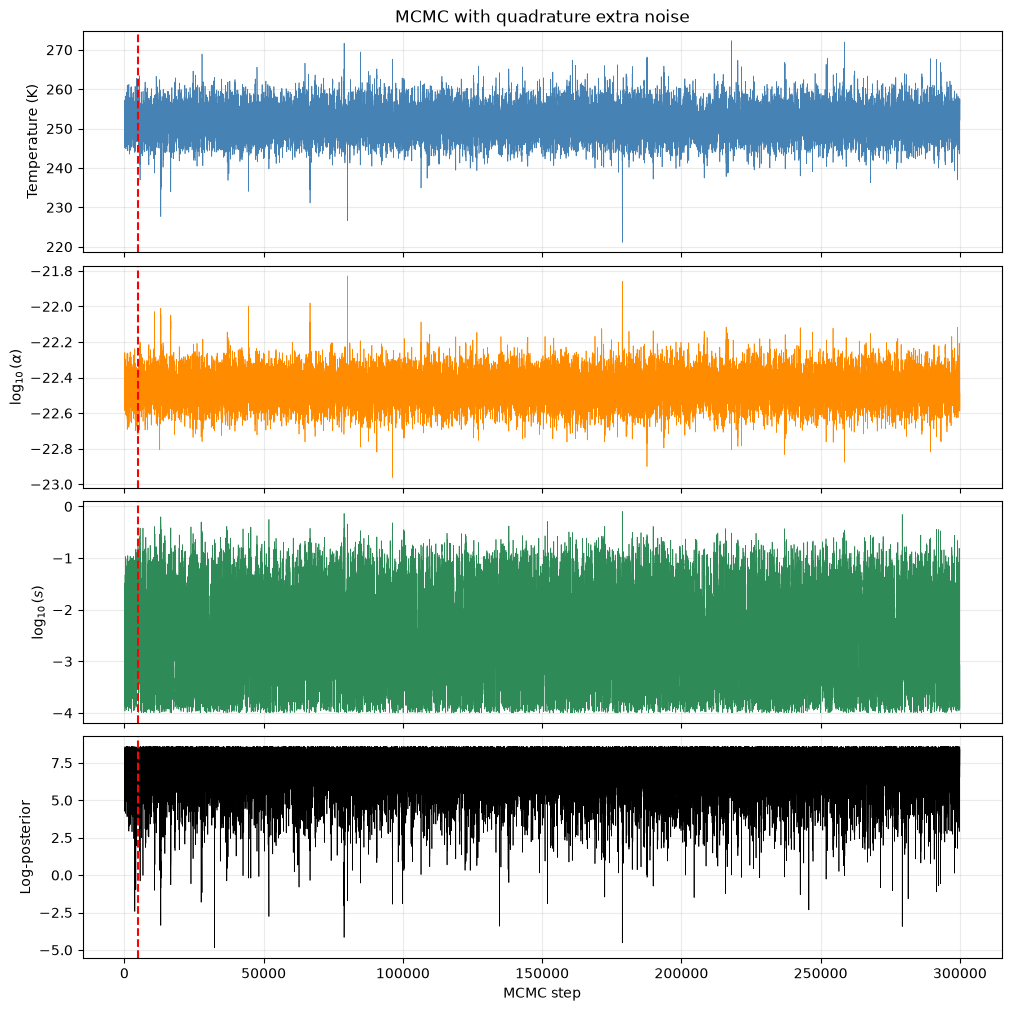


Temperature: 251.58 -3.47 +3.62 K
log10(alpha): -22.4593 -0.0805 +0.0803
Extra noise: 0.00249 -0.00220 +0.02159 dex
95% upper limit on extra noise: 0.064 dex


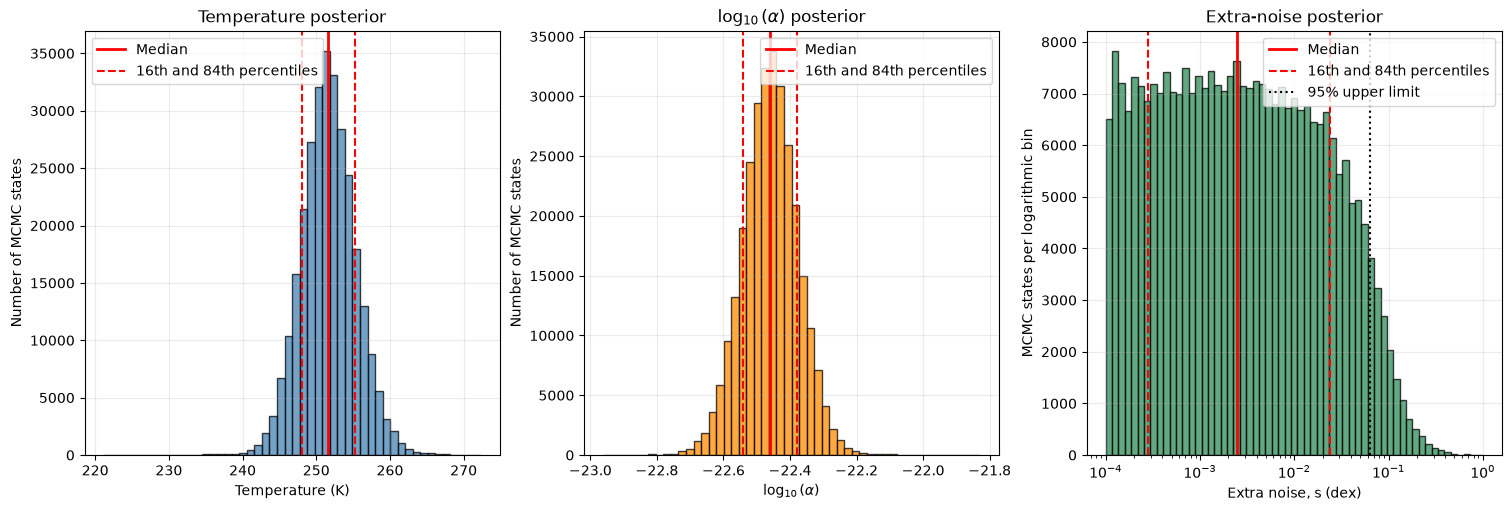

In [12]:
# ------------------------------------------------------------------
# Step 10: Add a quadrature extra-noise parameter
# ------------------------------------------------------------------

def log_likelihood_extra_noise(
    parameters,
    wavelength_m,
    observed_log_flux,
    observed_error
):
    """
    Gaussian log-likelihood with an extra-noise parameter.

    parameters[0] = temperature (K)
    parameters[1] = log10(alpha)
    parameters[2] = log10(extra noise in dex)
    """
    temperature, log_alpha, log_extra_noise = parameters

    # Convert log10(extra noise) back to extra noise in dex.
    extra_noise = 10**log_extra_noise

    # Add the extra noise and measurement error in quadrature.
    total_error = np.sqrt(observed_error**2 + extra_noise**2)

    predicted_log_flux = model_log_flux(
        wavelength_m,
        temperature,
        log_alpha
    )
    residuals = observed_log_flux - predicted_log_flux

    # Include the normalization because total_error depends on a parameter.
    return -0.5 * np.sum(
        (residuals / total_error)**2
        + np.log(2 * np.pi * total_error**2)
    )


def log_prior_extra_noise(parameters):
    """
    Uniform priors in T, log10(alpha), and log10(extra noise).

    The extra-noise bounds are 10**-4 to 10**0 dex.
    """
    temperature, log_alpha, log_extra_noise = parameters

    if (
        100.0 < temperature < 500.0
        and -30.0 < log_alpha < -15.0
        and -4.0 < log_extra_noise < 0.0
    ):
        return 0.0

    return -np.inf


def log_posterior_extra_noise(
    parameters,
    wavelength_m,
    observed_log_flux,
    observed_error
):
    """Log-posterior for the model with extra noise."""
    prior = log_prior_extra_noise(parameters)

    if not np.isfinite(prior):
        return -np.inf

    likelihood = log_likelihood_extra_noise(
        parameters,
        wavelength_m,
        observed_log_flux,
        observed_error
    )

    return prior + likelihood


def run_metropolis_extra_noise(
    initial_parameters,
    number_of_steps,
    temperature_jump,
    log_alpha_jump,
    log_extra_noise_jump,
    wavelength_m,
    observed_log_flux,
    observed_error,
    random_seed=1010
):
    """Run a three-parameter Metropolis chain."""
    rng = np.random.default_rng(random_seed)

    current_parameters = initial_parameters.copy()
    current_log_posterior = log_posterior_extra_noise(
        current_parameters,
        wavelength_m,
        observed_log_flux,
        observed_error
    )

    # Save the initial state, then save the state after every proposal.
    chain = [current_parameters.copy()]
    log_posterior_values = [current_log_posterior]

    accepted_moves = 0

    for _ in range(number_of_steps):
        proposed_parameters = np.array([
            current_parameters[0] + rng.normal(0.0, temperature_jump),
            current_parameters[1] + rng.normal(0.0, log_alpha_jump),
            current_parameters[2] + rng.normal(0.0, log_extra_noise_jump)
        ])

        proposed_log_posterior = log_posterior_extra_noise(
            proposed_parameters,
            wavelength_m,
            observed_log_flux,
            observed_error
        )

        # Metropolis rule written in terms of log-posterior values.
        log_acceptance_ratio = proposed_log_posterior - current_log_posterior

        if np.log(rng.random()) < log_acceptance_ratio:
            current_parameters = proposed_parameters
            current_log_posterior = proposed_log_posterior
            accepted_moves += 1

        chain.append(current_parameters.copy())
        log_posterior_values.append(current_log_posterior)

    acceptance_fraction = accepted_moves / number_of_steps

    return (
        np.asarray(chain),
        np.asarray(log_posterior_values),
        accepted_moves,
        number_of_steps,
        acceptance_fraction
    )


# ------------------------------------------------------------------
# Run the three-parameter MCMC
# ------------------------------------------------------------------

extra_noise_initial_parameters = np.array([
    250.0,   # Temperature in K
    -22.4,   # log10(alpha)
    -2.0     # log10(extra noise); extra noise = 0.01 dex
])

extra_noise_number_of_steps = 300000
# Keep the trace-based cutoff here: fitted errors change the likelihood
# normalization, so a raw chi-squared cutoff is not directly appropriate.
extra_noise_burn_in = 5000

# A wider log-noise proposal improves movement across the broad noise posterior.
# Keep the existing trace plots to inspect mixing.
extra_noise_temperature_jump = chosen_temperature_jump
extra_noise_log_alpha_jump = chosen_log_alpha_jump
extra_noise_log_noise_jump = 0.50

(
    extra_noise_chain,
    extra_noise_log_posterior,
    extra_noise_accepted_moves,
    extra_noise_proposed_moves,
    extra_noise_acceptance_fraction
) = run_metropolis_extra_noise(
    initial_parameters=extra_noise_initial_parameters,
    number_of_steps=extra_noise_number_of_steps,
    temperature_jump=extra_noise_temperature_jump,
    log_alpha_jump=extra_noise_log_alpha_jump,
    log_extra_noise_jump=extra_noise_log_noise_jump,
    wavelength_m=wavelength_m,
    observed_log_flux=observed_log_flux,
    observed_error=observed_error,
    random_seed=1010
)

print("Extra-noise model")
print("Accepted proposals:", extra_noise_accepted_moves)
print("Proposed moves:", extra_noise_proposed_moves)
print(f"Acceptance fraction: {extra_noise_acceptance_fraction:.3f}")
print("Saved chain states:", len(extra_noise_chain))

# ------------------------------------------------------------------
# Check the traces and mark the burn-in
# ------------------------------------------------------------------

fig, axes = plt.subplots(
    4, 1,
    figsize=(10, 10),
    sharex=True,
    constrained_layout=True
)

trace_labels = [
    "Temperature (K)",
    r"$\log_{10}(\alpha)$",
    r"$\log_{10}(s)$",
    "Log-posterior"
]

trace_values = [
    extra_noise_chain[:, 0],
    extra_noise_chain[:, 1],
    extra_noise_chain[:, 2],
    extra_noise_log_posterior
]

trace_colors = ["steelblue", "darkorange", "seagreen", "black"]

for ax, values, label, color in zip(
    axes, trace_values, trace_labels, trace_colors
):
    ax.plot(values, color=color, linewidth=0.5)
    ax.axvline(extra_noise_burn_in, color="red", linestyle="--")
    ax.set_ylabel(label)
    ax.grid(alpha=0.25)

axes[0].set_title("MCMC with quadrature extra noise")
axes[-1].set_xlabel("MCMC step")
if save == True:
    fig.savefig("Step_10.WISE0855_extra_noise_traces.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# Remove burn-in and prepare the posterior samples
# ------------------------------------------------------------------

extra_noise_posterior_chain = extra_noise_chain[extra_noise_burn_in:]

extra_noise_temperature_samples = extra_noise_posterior_chain[:, 0]
extra_noise_log_alpha_samples = extra_noise_posterior_chain[:, 1]
log_extra_noise_samples = extra_noise_posterior_chain[:, 2]

# Convert log10(extra noise) to extra noise in dex.
extra_noise_samples = 10**log_extra_noise_samples

# ------------------------------------------------------------------
# Calculate posterior summaries and credible intervals
# ------------------------------------------------------------------

temperature_16, temperature_50, temperature_84 = np.percentile(
    extra_noise_temperature_samples, [16, 50, 84]
)
log_alpha_16, log_alpha_50, log_alpha_84 = np.percentile(
    extra_noise_log_alpha_samples, [16, 50, 84]
)
noise_16, noise_50, noise_84 = np.percentile(
    extra_noise_samples, [16, 50, 84]
)

noise_upper_limit_95 = np.percentile(extra_noise_samples, 95)

print()
print(
    f"Temperature: {temperature_50:.2f} "
    f"-{temperature_50 - temperature_16:.2f} "
    f"+{temperature_84 - temperature_50:.2f} K"
)
print(
    f"log10(alpha): {log_alpha_50:.4f} "
    f"-{log_alpha_50 - log_alpha_16:.4f} "
    f"+{log_alpha_84 - log_alpha_50:.4f}"
)
print(
    f"Extra noise: {noise_50:.5f} "
    f"-{noise_50 - noise_16:.5f} "
    f"+{noise_84 - noise_50:.5f} dex"
)
print(f"95% upper limit on extra noise: {noise_upper_limit_95:.3f} dex")
# This upper limit is conditional on the chosen log-uniform noise prior.

# ------------------------------------------------------------------
# Plot the marginalized posterior distributions
# ------------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    constrained_layout=True
)

# Temperature posterior
axes[0].hist(
    extra_noise_temperature_samples,
    bins=50,
    color="steelblue",
    alpha=0.75,
    edgecolor="black"
)
axes[0].axvline(temperature_50, color="red", linewidth=2, label="Median")
axes[0].axvline(
    temperature_16,
    color="red",
    linestyle="--",
    label="16th and 84th percentiles"
)
axes[0].axvline(temperature_84, color="red", linestyle="--")
axes[0].set_xlabel("Temperature (K)")
axes[0].set_ylabel("Number of MCMC states")
axes[0].set_title("Temperature posterior")
axes[0].legend()
axes[0].grid(alpha=0.25)

# log10(alpha) posterior
axes[1].hist(
    extra_noise_log_alpha_samples,
    bins=50,
    color="darkorange",
    alpha=0.75,
    edgecolor="black"
)
axes[1].axvline(log_alpha_50, color="red", linewidth=2, label="Median")
axes[1].axvline(
    log_alpha_16,
    color="red",
    linestyle="--",
    label="16th and 84th percentiles"
)
axes[1].axvline(log_alpha_84, color="red", linestyle="--")
axes[1].set_xlabel(r"$\log_{10}(\alpha)$")
axes[1].set_ylabel("Number of MCMC states")
axes[1].set_title(r"$\log_{10}(\alpha)$ posterior")
axes[1].legend()
axes[1].grid(alpha=0.25)

# Extra-noise posterior
noise_bins = np.logspace(-4, 0, 60)
axes[2].hist(
    extra_noise_samples,
    bins=noise_bins,
    color="seagreen",
    alpha=0.75,
    edgecolor="black"
)
axes[2].axvline(noise_50, color="red", linewidth=2, label="Median")
axes[2].axvline(
    noise_16,
    color="red",
    linestyle="--",
    label="16th and 84th percentiles"
)
axes[2].axvline(noise_84, color="red", linestyle="--")
axes[2].axvline(noise_upper_limit_95, color="black", linestyle=":", label="95% upper limit")
axes[2].set_xscale("log")
axes[2].set_xlabel("Extra noise, s (dex)")
axes[2].set_ylabel("MCMC states per logarithmic bin")
axes[2].set_title("Extra-noise posterior")
axes[2].legend()
axes[2].grid(alpha=0.25)
if save == True:
    fig.savefig("Step_10.WISE0855_extra_noise_posteriors.png", dpi=300, bbox_inches="tight")
plt.show()

**What happens when we add extra noise?** We add a noise term $s$ using $\sigma_{\mathrm{tot},i}^2=\sigma_i^2+s^2$. The prior is uniform in $\log_{10}s$ from $-4$ to $0$. We keep the Gaussian normalization in the likelihood because it now depends on $s$.

The temperature stays near 251.58 K, with a slightly wider credible interval. With this prior, 95% of the sampled noise values are below 0.064 dex. A positive median for $s$ does not by itself show that extra noise is needed, because the prior does not allow zero. The noise histogram shows counts in logarithmic bins.

Temperature: 251.61 -3.33 +3.43 K
log10(alpha): -22.4598 -0.0777 +0.0777
Chi-squared at the posterior median parameters: 3.863


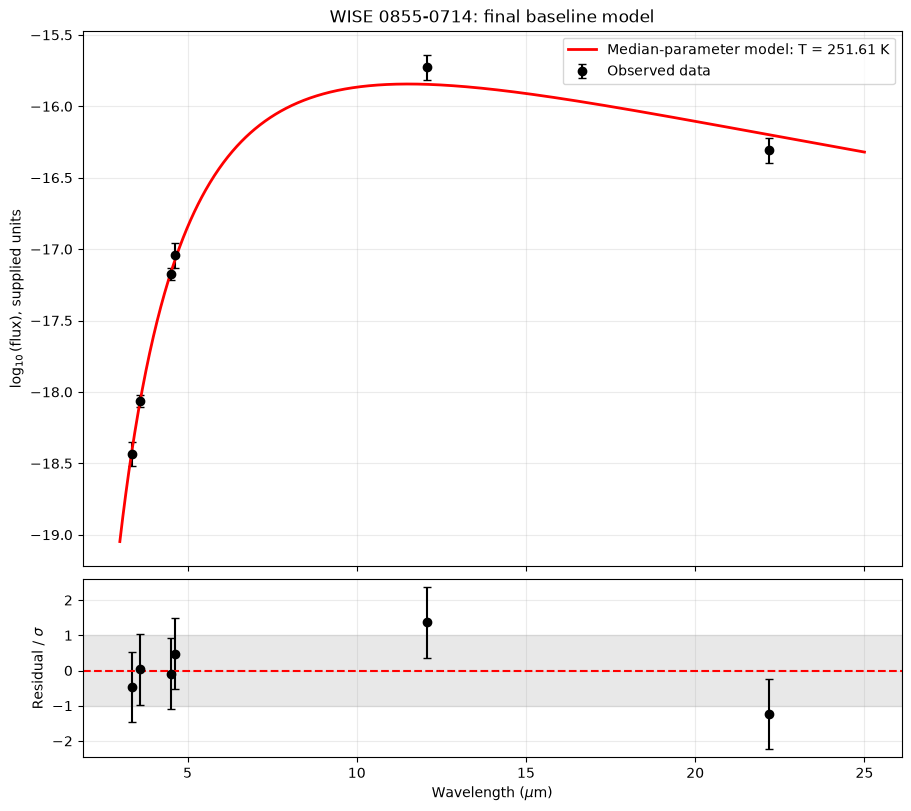

In [13]:
# ------------------------------------------------------------------
# Step 11: Final model and residuals: supporting plot for the presentation
# ------------------------------------------------------------------

# Use the combined baseline posterior from Step 8.
final_lower, final_median, final_upper = np.percentile(combined_posterior_chain,[16, 50, 84], axis=0)

final_temperature, final_log_alpha = final_median

# Print the posterior medians and 68% credible intervals.
print(
    f"Temperature: {final_temperature:.2f} "
    f"-{final_temperature - final_lower[0]:.2f} "
    f"+{final_upper[0] - final_temperature:.2f} K"
)

print(
    f"log10(alpha): {final_log_alpha:.4f} "
    f"-{final_log_alpha - final_lower[1]:.4f} "
    f"+{final_upper[1] - final_log_alpha:.4f}"
)

# Calculate the model on the smooth grid for plotting.
final_model_curve = model_log_flux(model_wavelength_m, final_temperature, final_log_alpha)

# Calculate the model at the observed wavelengths for the residuals.
final_model_at_data = model_log_flux(wavelength_m, final_temperature, final_log_alpha)

# Standardized residuals measure the difference in units of uncertainty.
final_residuals = (observed_log_flux - final_model_at_data) / observed_error

final_chi2 = chi_squared(final_median, wavelength_m, observed_log_flux, observed_error)

print(f"Chi-squared at the posterior median parameters: {final_chi2:.3f}")

# ------------------------------------------------------------------
# Plot the final model and standardized residuals
# ------------------------------------------------------------------
fig, axes = plt.subplots(
    2, 1,
    figsize=(9, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
    constrained_layout=True
)

axes[0].errorbar(
    wavelength_microns,
    observed_log_flux,
    yerr=observed_error,
    fmt="ko",
    capsize=3,
    label="Observed data"
)

axes[0].plot(
    model_wavelength_microns,
    final_model_curve,
    color="red",
    linewidth=2,
    label=f"Median-parameter model: T = {final_temperature:.2f} K"
)

axes[0].set_ylabel(r"$\log_{10}$(flux), supplied units")
axes[0].set_title("WISE 0855-0714: final baseline model")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Dividing the measurement errors by themselves gives unit error bars.
axes[1].errorbar(
    wavelength_microns,
    final_residuals,
    yerr=np.ones_like(observed_error),
    fmt="ko",
    capsize=3
)

axes[1].axhline(0, color="red", linestyle="--")
axes[1].axhspan(-1, 1, color="lightgray", alpha=0.5)

axes[1].set_xlabel(r"Wavelength ($\mu$m)")
axes[1].set_ylabel(r"Residual / $\sigma$")
axes[1].grid(alpha=0.25)
if save == True:
    fig.savefig("Step_11.WISE0855_final_model_and_residuals.png", dpi=300, bbox_inches="tight")
plt.show()

**Final model and presentation.** The model at the combined posterior medians has $\chi^2\approx3.86$. The residual plot shows how far each measurement is from that model in units of its stated error. The fitted blackbody temperature is $251.61^{+3.43}_{-3.33}$ K.